# DSC 530 Final Project — Film Representation and Box Office Performance, 1990–2015

**Ander (Trevor) McKee** · DSC530-T301 Data Exploration and Analysis · Summer 2026

---

**What the Bechdel test measures.** The Bechdel test is a measure of how women appear in a film. Level 1 is that the film has two named women; level 2 is that they speak to one another; level 3 is that they speak about something other than a man. Only level 3 is a pass.

**Research question.** Among commercially released US films from 1990 to 2015 with available dialogue data, how does a film's Bechdel test result relate to its box office performance, once production budget and release year are held fixed?

**The project data.** I've joined three independent public sources into one 798-film analysis table: (1) the Pudding film-dialogue data (character-level speech by gender), (2) bechdeltest.com's volunteer Bechdel ratings, and (3) The Numbers' production budgets and grosses. Acquisition, provenance, and known limitations are documented under Preliminary Preparation 1(b).

**Association, not causation.** The results below describe patterns, not effects. Nothing here supports a claim that changing a film's representation would change its revenue.

*Headings below follow the DSC 530 Final Project Guidelines exactly.*

In [1]:
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.formula.api as smf
from scipy import stats

pd.set_option("display.width", 120)
sns.set_theme(style="whitegrid")

INTERIM = Path.cwd().parent / "data" / "interim"
FIGS = Path.cwd().parent / "figures"

# spine and pud are earlier merge stages.
df = pd.read_csv(INTERIM / "analysis_table.csv")
spine = pd.read_csv(INTERIM / "spine.csv")
pud = pd.read_csv(INTERIM / "pudding_film.csv")

# Variables calculated here and reused throughout.
df["log_dom"] = np.log10(df["domestic_gross"])
df["log_ww"] = np.log10(df["worldwide_gross"])
df["log_budget"] = np.log10(df["production_budget"])
df["pass_"] = df["bechdel_pass"].astype(int)
df["pfd_10pp"] = df["pct_female_dialogue"] * 10   # 1 unit = 10 percentage points
df["year_c"] = df["year"] - 2000                  # centered for a readable intercept

core = ["production_budget", "domestic_gross", "worldwide_gross",
        "pct_female_dialogue", "pct_female_characters", "bechdel_rating"]

# Money columns scaled to $M.
MONEY = ["production_budget", "domestic_gross", "worldwide_gross"]
core_musd = df[core].copy()
core_musd[MONEY] /= 1e6
MUSD_LABELS = {c: (f"{c} ($M)" if c in MONEY else c) for c in core}

print(f"analysis table: {df.shape[0]} films x {df.shape[1]} columns, "
      f"{df['year'].min()}-{df['year'].max()}")

analysis table: 798 films x 29 columns, 1990-2015


---

# Preliminary Preparation Tasks

## 1. Dataset Selection

### a. Adequacy Check

The analysis table holds **798 films released 1990–2015**, each with a Bechdel rating, gender-coded dialogue measures, and production budget with domestic and worldwide gross. While there aren't as many films as I had hoped, 798 is large enough to support regression, classification, and clustering. They also contain every variable required by the research question: a representation measure (Bechdel rating, female dialogue share), an outcome (box office gross), and a control (production budget).

To say it plainly, the sample is **not** a random sample of all films. Each join favored larger, better-documented releases. I've done some work to quantify this imbalance, and I've tried to be honest about its limitations.

Coverage of the analysis sample:

films: 798
years: 1990-2015

budget range:          $450,000 - $306,000,000
domestic gross range:  $30,471 - $936,662,225
Bechdel pass rate:     49.5%

films per year (min/median/max): 8/31/58


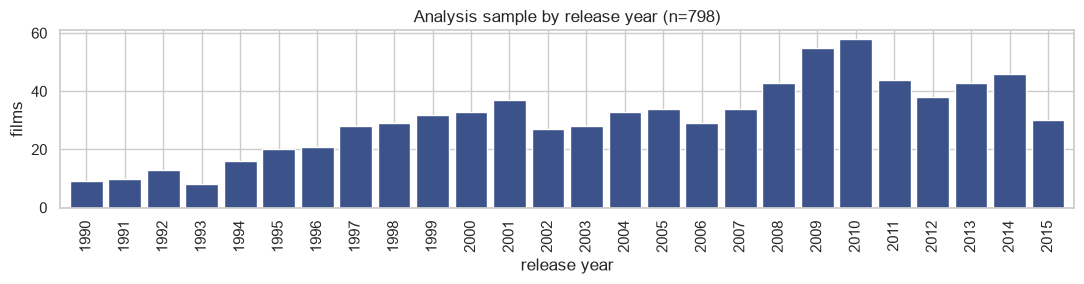

In [2]:
print("Coverage of the analysis sample:\n")
print(f"films: {len(df)}")
print(f"years: {df['year'].min()}-{df['year'].max()}")
print(f"\nbudget range:          ${df['production_budget'].min():,.0f} - ${df['production_budget'].max():,.0f}")
print(f"domestic gross range:  ${df['domestic_gross'].min():,.0f} - ${df['domestic_gross'].max():,.0f}")
print(f"Bechdel pass rate:     {df['bechdel_pass'].mean():.1%}")
print(f"\nfilms per year (min/median/max): "
      f"{df.groupby('year').size().min()}/{df.groupby('year').size().median():.0f}/{df.groupby('year').size().max()}")

# Plot films per release year.
fig, ax = plt.subplots(figsize=(11, 3))
df.groupby("year").size().plot.bar(ax=ax, width=0.85, color="#3b528b")
ax.set_ylabel("films"); ax.set_xlabel("release year")
ax.set_title(f"Analysis sample by release year (n={len(df)})")
fig.tight_layout()
fig.savefig(FIGS / "final_year_coverage.png", dpi=150)
plt.show()

### b. Data Integrity

#### Source information and collection:

| Source | What it has | How it was collected |
|---|---|---|
| **The Pudding** screenplay collection | character-level word counts with gender and age, 2,000 films | Screenplays scraped and parsed by Hanah Anderson & Matt Daniels (2016); characters gender-coded against IMDb cast lists |
| **bechdeltest.com** | Bechdel rating 0–3 per film | Submitted and reviewed by volunteers; accessed through the TidyTuesday 2021-03-09 mirror |
| **The Numbers** | production budget, domestic and worldwide gross | Industry reporting compiled by Nash Information Services; accessed through two static mirrors (TidyTuesday 2018, WWU DATA 311 2023) |

#### Known biases

1. **Volunteer rating.** Bechdel ratings are contributed by site visitors. Films that attract attention for representation reasons are more likely to be rated, and ratings can be disputed (however, in the mirror, none carry the dubious tag).
2. **Screenplay availability.** The Pudding data only covers films whose scripts were publicly available, which skews toward commercially successful English-language releases.
3. **Binary gender coding.** Characters are coded male/female against IMDb. IMDb does not reference non-binary identities and can misclassify. There were five characters coded as `?`, all of whom were excluded during cleaning.
4. **Selection funnel.** Each time I joined a set, the sample got smaller and favored larger films.

**Variable-names.** There are two different measures of "gross" across sources: The Numbers reports **nominal** dollars, while the Pudding set reports **inflation-adjusted** dollars. The primary outcome uses nominal gross with a year control; the inflation-adjusted figure appears only as a check.

In [3]:
# The selection funnel.
pud_w = pud[pud["year"].between(1990, 2015)]
stages = {
    "1. Pudding window":   pud_w,
    "2. + Bechdel rated":  spine,
    "3. + budget matched": df,
}

# One row per merge stage.
funnel = pd.DataFrame({
    name: {
        "films": len(d),
        "mean $M": d["gross_infl_adj_musd"].mean(),
        "median $M": d["gross_infl_adj_musd"].median(),
        "% f. dialogue": 100 * d["pct_female_dialogue"].mean(),
    }
    for name, d in stages.items()
}).T

n = funnel["films"]
funnel.insert(1, "% kept", 100 * n / n.shift())        # of the previous stage
funnel.insert(2, "% of start", 100 * n / n.iloc[0])    # of the original 1,587
funnel["films"] = n.astype(int)

print("Selection funnel — every stage keeps larger films\n")
print(funnel.to_string(float_format=lambda v: f"{v:,.1f}", na_rep="—"))
print(f"\nNet loss: {int(n.iloc[0]):,} -> {int(n.iloc[-1]):,} films "
      f"({100*(1-n.iloc[-1]/n.iloc[0]):.1f}% dropped); "
      f"mean gross grew from ${funnel['mean $M'].iloc[0]:.0f}M -> ${funnel['mean $M'].iloc[-1]:.0f}M")

Selection funnel — every stage keeps larger films

                     films  % kept  % of start  mean $M  median $M  % f. dialogue
1. Pudding window     1587       —       100.0     92.9       50.0           29.0
2. + Bechdel rated    1189    74.9        74.9    105.9       62.0           30.0
3. + budget matched    798    67.1        50.3    124.9       80.0           28.3

Net loss: 1,587 -> 798 films (49.7% dropped); mean gross grew from $93M -> $125M


The funnel is the core limitation of this project, and I'm treating it more like a finding. The mean inflation-adjusted gross grows from **\\$93M → \\$106M → \\$125M**
across the joins. The films that remain are systematically bigger than the films that get removed, so the estimates below describe *commercially successful, well-documented films*.

## 2. Data Cleaning and Preparation

### a. Handle missing values or outliers

**Missing values.** Four columns carry missing data. The pattern is structural; there's a visualization in EDA 2(b)(iii). I did not impute any data. The missing metadata columns are used only in a check. There is no good reason to impute a film's genre or MPAA rating here.

**Outliers.** I did not trim any observations. The extreme values in gross and budget are actual films; I verified them against a second independent source, where cross-source gross agreement was r = 0.981. They do, however, skew the data, which is why I log transform in 2(c).

In [4]:
# Missing count and rate per column.
missing = df.isna().sum()
missing = missing[missing > 0].to_frame("missing")
missing["% of rows"] = 100 * missing["missing"] / len(df)
print("Columns with missing values:\n")
print(missing.to_string(float_format=lambda v: f"{v:,.1f}"))

complete = df.notna().all(axis=1).sum()
print(f"\nComplete rows across all columns: {complete} of {len(df)} ({100*complete/len(df):.1f}%)")

# Five largest grosses; ratio as a check.
top = df.nlargest(5, "domestic_gross")[
    ["title", "year", "production_budget", "domestic_gross"]].copy()
top["budget $M"] = top["production_budget"] / 1e6
top["domestic $M"] = top["domestic_gross"] / 1e6
top["gross/budget"] = top["domestic_gross"] / top["production_budget"]
top = top[["title", "year", "budget $M", "domestic $M", "gross/budget"]]

# Pad the header to left-align.
w = int(top["title"].str.len().max())
top = top.rename(columns={"title": f"{'title':<{w}}"})

print("\nOutlier check:\n")
print(top.to_string(index=False, formatters={
    f"{'title':<{w}}": lambda s: f"{s:<{w}}",
    "budget $M": lambda v: f"{v:,.1f}",
    "domestic $M": lambda v: f"{v:,.1f}",
    "gross/budget": lambda v: f"{v:.2f}x",
}))
print(f"\nMedian gross/budget across all {len(df)} films: "
      f"{(df['domestic_gross'] / df['production_budget']).median():.2f}x")

Columns with missing values:

                     missing  % of rows
gross_infl_adj_musd        9        1.1
distributor               87       10.9
mpaa_rating               87       10.9
genre                     87       10.9

Complete rows across all columns: 702 of 798 (88.0%)

Outlier check:

title                                       year budget $M domestic $M gross/budget
Star Wars: Episode VII - The Force Awakens  2015     306.0       936.7        3.06x
Avatar                                      2009     237.0       785.2        3.31x
Titanic                                     1997     200.0       666.1        3.33x
The Avengers                                2012     225.0       623.4        2.77x
The Dark Knight                             2008     185.0       535.0        2.89x

Median gross/budget across all 798 films: 1.39x


### b. Recoding or encoding of variables

Four derived variables are created. Each is a recoding:

| New variable | Derived from | Why |
|---|---|---|
| `bechdel_pass` / `pass_` | `bechdel_rating == 3` | The Bechdel test is usually read as pass/fail. Rating 3 means all three criteria are met. I kept this alongside the full 0–3 ordinal, which is used in a check. |
| `pfd_10pp` | `pct_female_dialogue × 10` | There is no film where women speak 100% of the dialogue. I rescale to the existing range, so one unit is a 10-percentage-point shift. |
| `year_c` | `year − 2000` | Centering on the year 2000 puts the intercept within the range of films, even though it can't be fairly interpreted. |
| `log_dom`, `log_ww`, `log_budget` | `log10` of each | See 2(c). |

Categorical variables (`genre`, `mpaa_rating`) are left as strings and encoded only where a model needs them, so the reference category stays visible in the output. The regression in 5(a) uses `statsmodels`' `C()`; the classifier in 5(b) uses scikit-learn's `OneHotEncoder` inside a pipeline, with Drama and R as the reference categories.

In [5]:
# Confirm bechdel_pass is exactly rating == 3.
print("Encoding check — bechdel_rating (0-3 ordinal) to bechdel_pass (binary):\n")
print(pd.crosstab(df["bechdel_rating"], df["bechdel_pass"],
                  rownames=["bechdel_rating"], colnames=["bechdel_pass"]).to_string())
print(f"\npass rate: {df['bechdel_pass'].mean():.1%}  ({df['pass_'].sum()} of {len(df)} films)")
print(f"\npfd_10pp range: {df['pfd_10pp'].min():.2f} to {df['pfd_10pp'].max():.2f} "
      f"(one unit = 10 percentage points of dialogue)")

Encoding check — bechdel_rating (0-3 ordinal) to bechdel_pass (binary):

bechdel_pass    False  True 
bechdel_rating              
0                  49      0
1                 259      0
2                  95      0
3                   0    395

pass rate: 49.5%  (395 of 798 films)

pfd_10pp range: 0.00 to 9.19 (one unit = 10 percentage points of dialogue)


### c. Data transformation if certain variables are skewed or have extreme values

The three money variables are severely right-skewed (see EDA 2(a)): domestic gross has skewness 2.84 and kurtosis 13.40, and worldwide gross 3.66 and 23.40, against 0 for a normal distribution.

A **base-10 log transform** is applied to budget and both gross measures. Here is the justification:

1. Box office revenue is multiplicative (a film earns some *multiple* of its budget) so differences are naturally proportional.
2. If left untransformed, some blockbusters would dominate a least-squares fit.
3. On the log scale a regression coefficient reads as a **percentage** difference, which is how the result is reported.

`log10` is chosen over natural log for interpretability: one unit is one order of magnitude. `domestic_gross` has no
zero or negative values (minimum \\$30,471).

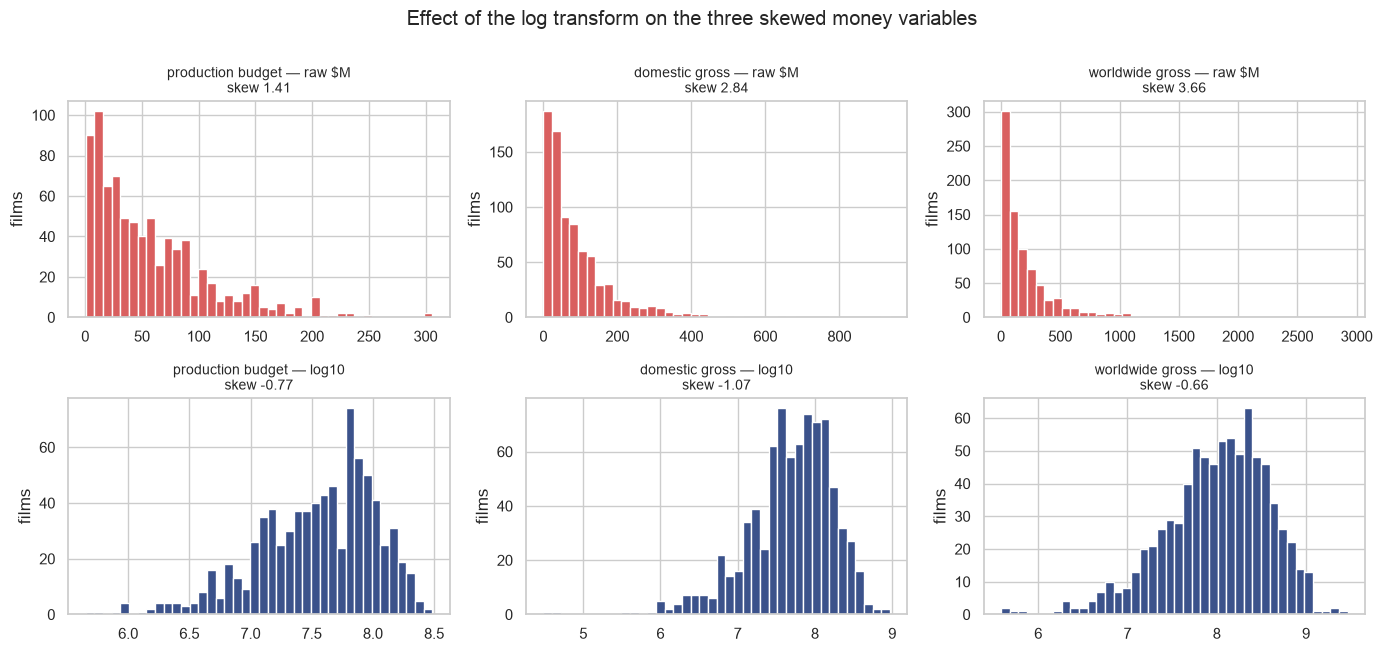

Skewness before and after the log10 transform:

                   raw skew  log10 skew
production_budget     1.407      -0.767
domestic_gross        2.841      -1.071
worldwide_gross       3.663      -0.661


In [6]:
fig, axes = plt.subplots(2, 3, figsize=(14, 6.5))
# Plot top row raw scale, bottom row log10; one column per variable.
for j, (colname, label) in enumerate([("production_budget", "production budget"),
                                      ("domestic_gross", "domestic gross"),
                                      ("worldwide_gross", "worldwide gross")]):
    axes[0, j].hist(df[colname] / 1e6, bins=40, color="#d95f5f", edgecolor="white")
    axes[0, j].set_title(f"{label} — raw $M\nskew {df[colname].skew():.2f}", fontsize=10)
    axes[1, j].hist(np.log10(df[colname]), bins=40, color="#3b528b", edgecolor="white")
    axes[1, j].set_title(f"{label} — log10\nskew {np.log10(df[colname]).skew():.2f}", fontsize=10)
    for r in (0, 1):
        axes[r, j].set_ylabel("films")
fig.suptitle("Effect of the log transform on the three skewed money variables", y=1.00)
fig.tight_layout()
fig.savefig(FIGS / "final_log_transform.png", dpi=150)
plt.show()

# Print skew stats.
print("Skewness before and after the log10 transform:\n")
print(pd.DataFrame({
    "raw skew": [df[c].skew() for c in ["production_budget", "domestic_gross", "worldwide_gross"]],
    "log10 skew": [np.log10(df[c]).skew() for c in ["production_budget", "domestic_gross", "worldwide_gross"]],
}, index=["production_budget", "domestic_gross", "worldwide_gross"]).round(3).to_string())

### d. Normalization or Standardization

Standardizing depends on the algorithm used, so it's decided per model:

- **Regression (5a) — not standardized.** Ordinary least squares doesn't change fitted values, R², and p-values with standardization. Leaving budget on the log-dollar scale keeps the coefficients interpretable.
- **Classification (5b) — standardized.** Predictors on larger scales are penalized unfairly. Standardization is used inside a `Pipeline` so it's fit on training folds only.
- **Clustering (6a) — standardized.** k-means minimizes "Euclidean distance". Without scaling, the variables that span millions would determine clusters over `pct_female_dialogue` which spans 0 to 0.92.

---

# Exploratory Data Analysis (EDA) Tasks

## 1. Describe the Variable Characteristics with Summary Statistics

### a. Provide description of the variables you are using in this project

The table below documents each variable used in the analysis. Other variables exist in the analysis table that are used to derive variables here.

In [49]:
data_dict = pd.read_csv(INTERIM / "data_dictionary.csv")

# Only the columns this analysis actually uses.
USED = ["imdb_id", "title", "year", "gross_infl_adj_musd",
        "pct_female_dialogue", "pct_female_characters",
        "bechdel_rating", "bechdel_pass",
        "production_budget", "domestic_gross", "worldwide_gross",
        "distributor", "mpaa_rating", "genre", "source"]

# Fail if a documented column is not in the table.
table_cols = set(pd.read_csv(INTERIM / "analysis_table.csv").columns)
assert set(USED) <= table_cols, f"documented column missing from the table: {set(USED) - table_cols}"

# Reworded for simplicity.
REWORDED = {
    "imdb_id": "IMDb id; used as join key for Bechdel",
    "gross_infl_adj_musd": "domestic gross, inflation-adjusted $M",
    "pct_female_dialogue": "share of all spoken words from female-coded characters",
    "pct_female_dialogue": "share of all spoken words from female-coded characters",
    "pct_female_characters": "share of speaking characters who are female-coded",
    "bechdel_pass": "bechdel_rating == 3",
    "production_budget": "production budget, nominal USD",
    "domestic_gross": "US/Canada gross, nominal USD",
    "worldwide_gross": "worldwide gross, nominal USD",
    "genre": "single primary genre",
}
data_dict = data_dict[data_dict["column"].isin(USED)].set_index("column").loc[USED].reset_index()
data_dict["description"] = data_dict.apply(
    lambda r: REWORDED.get(r["column"], r["description"]), axis=1)

print(f"Data dictionary — {len(data_dict)} variables used in this analysis "
      f"(of {len(table_cols)} columns in the table)")

display(data_dict.style.hide(axis="index")
        .set_properties(**{"text-align": "left"})
        .set_table_styles([{"selector": "th", "props": [("text-align", "left")]}]))

Data dictionary — 15 variables used in this analysis (of 23 columns in the table)


column,source,description
imdb_id,Pudding meta_data7,IMDb id; used as join key for Bechdel
title,Pudding meta_data7,film title as recorded by Pudding
year,Pudding meta_data7,release year per Pudding; window filter 1990-2015 applied
gross_infl_adj_musd,Pudding meta_data7,"domestic gross, inflation-adjusted $M"
pct_female_dialogue,derived,share of all spoken words from female-coded characters
pct_female_characters,derived,share of speaking characters who are female-coded
bechdel_rating,Bechdel mirror 2021,0-3 ordinal: 2+ women / who talk / about something besides a man
bechdel_pass,derived,bechdel_rating == 3
production_budget,Numbers union,"production budget, nominal USD"
domestic_gross,Numbers union,"US/Canada gross, nominal USD"


In [8]:
# Money in $M to avoid scientific notation.
desc = core_musd.describe().T.drop(columns="count")
desc.index = [MUSD_LABELS[c] for c in core]

print(f"Summary statistics for the analysis variables (n = {len(df)} films)\n")
print(desc.to_string(float_format=lambda v: f"{v:,.2f}"))


Summary statistics for the analysis variables (n = 798 films)

                         mean    std  min   25%    50%    75%      max
production_budget ($M)  56.45  50.33 0.45 16.50  40.00  80.00   306.00
domestic_gross ($M)     88.58  98.73 0.03 25.63  56.45 119.35   936.66
worldwide_gross ($M)   202.74 262.17 0.38 46.09 112.42 258.51 2,923.71
pct_female_dialogue      0.28   0.20 0.00  0.13   0.23   0.39     0.92
pct_female_characters    0.31   0.16 0.00  0.20   0.30   0.42     0.89
bechdel_rating           2.05   1.03 0.00  1.00   2.00   3.00     3.00


## 2. Conduct Univariate Analysis

### a. Calculate descriptive statistics (mean, median, mode, variance, skewness, kurtosis)

In [9]:
# Money in $M, so variance is in ($M)^2.
moments = pd.DataFrame({
    "mean": core_musd.mean(),
    "median": core_musd.median(),
    "mode": core_musd.mode().iloc[0],
    "variance": core_musd.var(),
    "skewness": core_musd.skew(),
    "kurtosis": core_musd.kurt(),   # Fisher definition: 0 = normal, > 0 = heavy-tailed
})

# Set up rounding to two or three decimals.
two, three = (lambda v: f"{v:,.2f}"), (lambda v: f"{v:,.3f}")

print("Required descriptive statistics for the key variables")
print("(money variables in $M; variance in ($M)^2)\n")

# Print and apply rounding.
print(moments.rename(index=MUSD_LABELS).to_string(
    formatters={"mean": two, "median": two, "mode": two,
                "variance": three, "skewness": two, "kurtosis": two}))

# Count the mode.
print("\nFrequency of each mode")
for c in core:
    modal = moments.loc[c, "mode"]
    n = int((core_musd[c] == modal).sum())
    unit = " $M" if c in MONEY else ""
    if n == 1:
        # Declare if no mode (mode appears once).
        print(f"  {c:24s} no mode — no value occurs more than once")
    else:
        print(f"  {c:24s} mode {modal:>10,.4g}{unit:3s} occurs {n:3d}x of {len(df)}")


Required descriptive statistics for the key variables
(money variables in $M; variance in ($M)^2)

                         mean median  mode   variance skewness kurtosis
production_budget ($M)  56.45  40.00 35.00  2,532.855     1.41     2.18
domestic_gross ($M)     88.58  56.45  0.03  9,747.558     2.84    13.40
worldwide_gross ($M)   202.74 112.42  0.38 68,735.652     3.66    23.40
pct_female_dialogue      0.28   0.23  0.00      0.040     0.96     0.25
pct_female_characters    0.31   0.30  0.33      0.027     0.54     0.08
bechdel_rating           2.05   2.00  3.00      1.064    -0.43    -1.34

Frequency of each mode
  production_budget        mode         35 $M occurs  30x of 798
  domestic_gross           no mode — no value occurs more than once
  worldwide_gross          no mode — no value occurs more than once
  pct_female_dialogue      mode          0    occurs  18x of 798
  pct_female_characters    mode     0.3333    occurs  63x of 798
  bechdel_rating           mode          3

**My analysis**

The mode isn't very useful for the money variables, and the frequency explains that. Domestic and worldwide gross are continuous, so every value is unique. Production budget is the exception because studios set budgets at round numbers. The mode is informative only for `bechdel_rating`, where 3 occurs 395 times.

Skewness and kurtosis are what justify the log transform of certain variables. Worldwide gross has skewness at 3.66 and kurtosis at 23.40, domestic gross at 2.84 and 13.40 (severe right tails).

### b. Create visualization of the key variables to examine distribution or patterns

#### i. Histograms, box plots, and density plots for numerical variables; bar charts for categorical

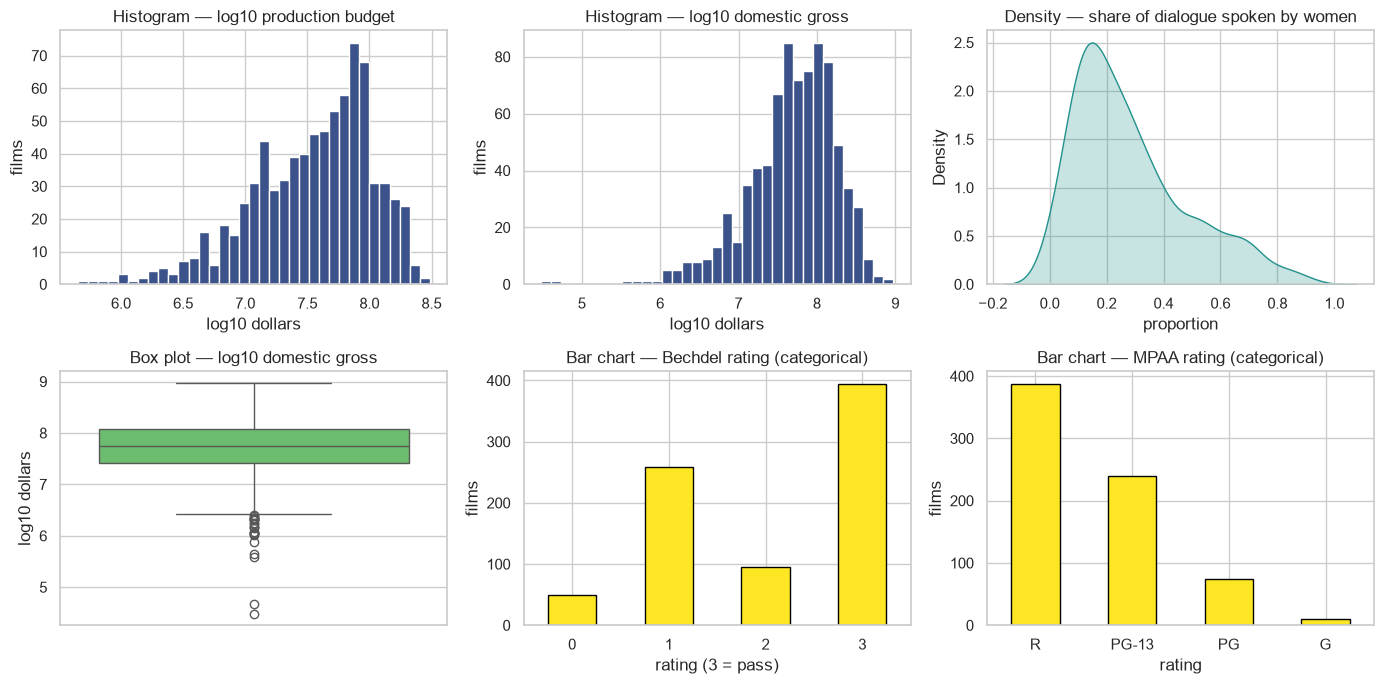

In [50]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7))

# One panel per plot type: histogram, density, box, bar.
axes[0, 0].hist(df["log_budget"], bins=35, color="#3b528b", edgecolor="white")
axes[0, 0].set_title("Histogram — log10 production budget")
axes[0, 0].set_xlabel("log10 dollars"); axes[0, 0].set_ylabel("films")

axes[0, 1].hist(df["log_dom"], bins=35, color="#3b528b", edgecolor="white")
axes[0, 1].set_title("Histogram — log10 domestic gross")
axes[0, 1].set_xlabel("log10 dollars"); axes[0, 1].set_ylabel("films")

sns.kdeplot(data=df, x="pct_female_dialogue", fill=True, color="#21918c", ax=axes[0, 2])
axes[0, 2].set_title("Density — share of dialogue spoken by women")
axes[0, 2].set_xlabel("proportion")

sns.boxplot(data=df, y="log_dom", ax=axes[1, 0], color="#5ec962")
axes[1, 0].set_title("Box plot — log10 domestic gross")
axes[1, 0].set_ylabel("log10 dollars")

df["bechdel_rating"].value_counts().sort_index().plot.bar(
    ax=axes[1, 1], color="#fde725", edgecolor="black")
axes[1, 1].set_title("Bar chart — Bechdel rating (categorical)")
axes[1, 1].set_xlabel("rating (3 = pass)"); axes[1, 1].set_ylabel("films")
axes[1, 1].tick_params(axis="x", labelrotation=0)

df["mpaa_rating"].value_counts().plot.bar(ax=axes[1, 2], color="#fde725", edgecolor="black")
axes[1, 2].set_title("Bar chart — MPAA rating (categorical)")
axes[1, 2].set_xlabel("rating"); axes[1, 2].set_ylabel("films")
axes[1, 2].tick_params(axis="x", labelrotation=0)

fig.tight_layout()
fig.savefig(FIGS / "final_univariate.png", dpi=150)
plt.show()

The two log-scale histograms are nearly symmetric and unimodal, which meant the transform did well. Female dialogue share is right-skewed with a spike at zero (18 films have no female speech at all). The Bechdel bar chart shows most films at a rating of 1 or 3, and MPAA shows most films were rated R and PG-13.

#### ii. Visualizing outliers and skewness, and the method applied

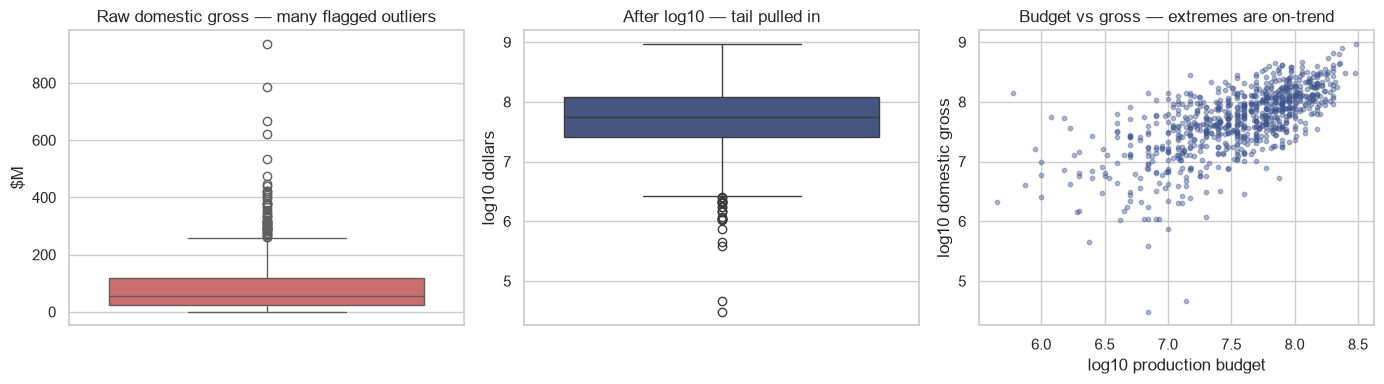

Points flagged as outliers by the 1.5 x IQR rule:

  domestic_gross, raw scale:    49 of 798
  domestic_gross, log10 scale:  24 of 798


In [11]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

# Same variable before and after log10, then budget vs gross.
sns.boxplot(data=df, y=df["domestic_gross"] / 1e6, ax=axes[0], color="#d95f5f")
axes[0].set_title("Raw domestic gross — many flagged outliers")
axes[0].set_ylabel("$M")

sns.boxplot(data=df, y="log_dom", ax=axes[1], color="#3b528b")
axes[1].set_title("After log10 — tail pulled in")
axes[1].set_ylabel("log10 dollars")

axes[2].scatter(df["log_budget"], df["log_dom"], s=10, alpha=0.4, color="#3b528b")
axes[2].set_xlabel("log10 production budget"); axes[2].set_ylabel("log10 domestic gross")
axes[2].set_title("Budget vs gross — extremes are on-trend")

fig.tight_layout()
fig.savefig(FIGS / "final_outliers.png", dpi=150)
plt.show()

# Count points outside 1.5 x IQR.
def iqr_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()

print("Points flagged as outliers by the 1.5 x IQR rule:\n")
print(f"  domestic_gross, raw scale:   {iqr_outliers(df['domestic_gross']):3d} of {len(df)}")
print(f"  domestic_gross, log10 scale: {iqr_outliers(df['log_dom']):3d} of {len(df)}")

No observations are removed. Even though the raw-scale box plot flags a large number of films as outliers, the scatter plot explains why that's misleading: the high-grossing films sit on trend with high budget–gross. They are films that spend big and earn proportionally; they are not invalid data.

The 1.5 × IQR rule works well on a roughly symmetric distribution, so on a right-skewed distribution, you mostly just detect the skew. Applying the log transform reduces flagged outliers. So the **method used is transformation, not trimming**.

#### iii. Visualize missing data to identify patterns in missingness

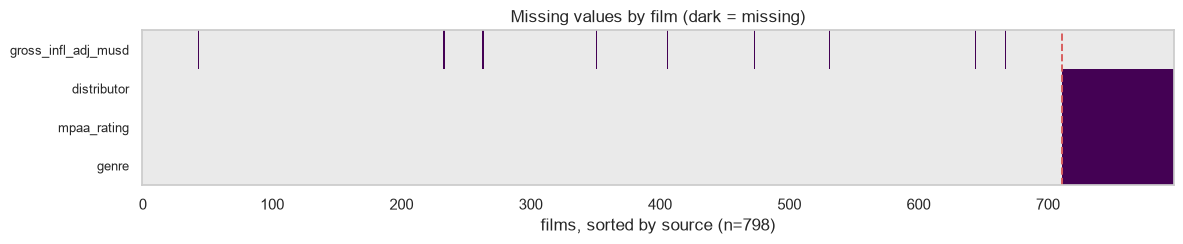

In [12]:
miss_cols = df.columns[df.isna().any()].tolist()
ordered = df.sort_values("source").reset_index(drop=True)

# Transposed so there are enough pixels for the range of films.
missing_matrix = ordered[miss_cols].isna().to_numpy().T

fig, ax = plt.subplots(figsize=(12, 2.6))
ax.imshow(missing_matrix, aspect="auto", interpolation="nearest",
          cmap=matplotlib.colors.ListedColormap(["#eaeaea", "#440154"]))

# Draw red boundary line.
boundary = int((ordered["source"] == "tidytuesday_2018").sum())
ax.axvline(boundary, color="#d95f5f", lw=1.4, ls="--")

ax.set_yticks(range(len(miss_cols)))
ax.set_yticklabels(miss_cols, fontsize=9)
ax.set_xlabel(f"films, sorted by source (n={len(df)})")
ax.set_title("Missing values by film (dark = missing)")
ax.grid(False)
fig.tight_layout()
fig.savefig(FIGS / "final_missingness.png", dpi=150)
plt.show()

**The missingness does not appear to be critical.** All 87 films missing `distributor`, `mpaa_rating`, and `genre` are missing all three at the same time. They're all from the `wwu_mirror_2023`.

This is an issue with the mirror, because its pages only had rank, date, title, budget, and the two grosses. These aren't films that just decline to report a genre. Since the missingness is explainable by the datasets, there is little practical consequence. The genre check simply runs on the 711 films that include ratings. Additionally, the 9 films that are missing `gross_infl_adj_musd` values come from random gaps in the Pudding data. They are not systematically missing and can be ignored.

## 3. Conduct Bivariate Analysis

### a. Calculate covariance and correlation

#### i. Pearson correlation for continuous values

In [13]:
# Mask the lower-left of the matrices.
def mask_lower(frame):
    return frame.where(~np.tril(np.ones(frame.shape, dtype=bool), k=-1))


# Money in $M.
print("Covariance matrix (money variables in $M, so those cells are in ($M)^2):\n")
print(mask_lower(core_musd.cov()).rename(index=MUSD_LABELS, columns=MUSD_LABELS)
      .to_string(float_format=lambda v: f"{v:,.3f}", na_rep=""))

print("\n\nPearson correlation matrix (the same information rescaled to [-1, 1]):\n")
print(mask_lower(core_musd.corr()).rename(index=MUSD_LABELS, columns=MUSD_LABELS)
      .to_string(float_format=lambda v: f"{v:.3f}", na_rep=""))

# Budget by Bechdel rating.
by_rating = df.groupby("bechdel_rating")["production_budget"].agg(
    films="size",
    mean_budget_M=lambda s: s.mean() / 1e6,
    median_budget_M=lambda s: s.median() / 1e6,
).round(1)
print("\n\nProduction budget by Bechdel rating:\n")
print(by_rating.to_string())

Covariance matrix (money variables in $M, so those cells are in ($M)^2):

                        production_budget ($M)  domestic_gross ($M)  worldwide_gross ($M)  pct_female_dialogue  pct_female_characters  bechdel_rating
production_budget ($M)               2,532.855            3,241.406             9,170.306               -2.221                 -2.283          -6.150
domestic_gross ($M)                                       9,747.558            24,597.197               -2.488                 -2.815           2.044
worldwide_gross ($M)                                                           68,735.652               -6.216                 -7.665           5.271
pct_female_dialogue                                                                                      0.040                  0.025           0.113
pct_female_characters                                                                                                           0.027           0.083
bechdel_rating            

**Covariance and correlation are the same information, but correlation is scaled.** Covariance is measured in the product of two variables' units, so there is no use in comparing different unit-pairs. For example, the budget–gross covariance is 3,241 ($M)², and the dialogue–characters covariance is 0.025. Neither number means anything next to the other. Correlation takes the covariance as the numerator and divides by both standard deviations to bound the values to [-1, 1]. 

Covariance is still relevant to compare the three money variables. Budget covaries about 2.8× more with worldwide gross (9,170) than with domestic gross (3,241), even though the two correlations are about the same (0.695 and 0.652). Worldwide revenue is a larger quantity with more room to move.

**The budget gap is considerable between ratings 1 and 2.** Correlation reports budget and Bechdel correlate at −0.16. I included the breakdown to show that the drop doesn't happen sequentially. Median budget falls \\$7M from rating 0 to 1, then **\\$25M from rating 1 to 2**, then rises \\$5M from 2 to 3. Rating 1 means a film has two named women. Rating 2 means they speak to each other, and that's where the key difference is in budgeting.

### b. Create visualization

#### i. Scatter plots, density plots, and a correlation heatmap

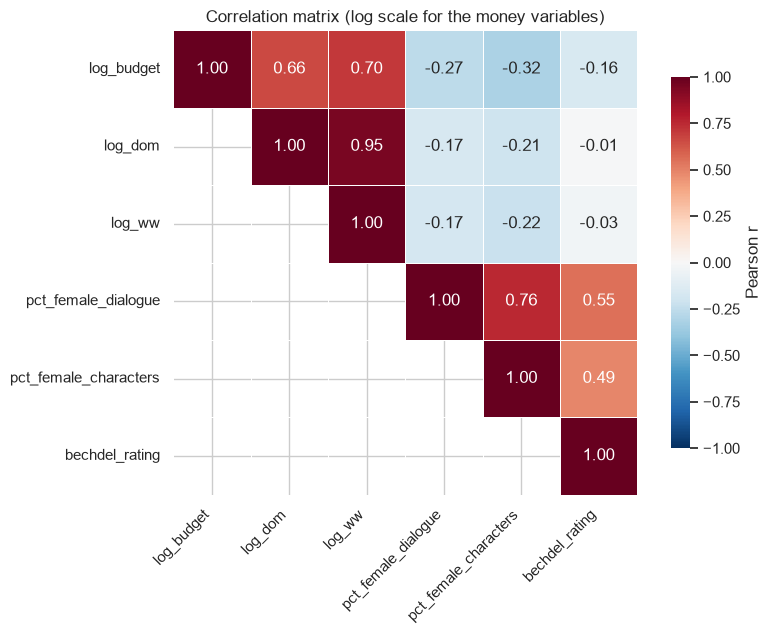

In [14]:
corr_vars = ["log_budget", "log_dom", "log_ww", "pct_female_dialogue",
             "pct_female_characters", "bechdel_rating"]

corr = df[corr_vars].corr()

# Mask the lower-left of the matrix.
mask = np.tril(np.ones_like(corr, dtype=bool), k=-1)

fig, ax = plt.subplots(figsize=(8.5, 6.5))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r",
            vmin=-1, vmax=1, center=0, square=True, ax=ax, linewidths=0.5,
            cbar_kws={"label": "Pearson r", "shrink": 0.8})
ax.set_title("Correlation matrix (log scale for the money variables)")
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right")
ax.set_yticklabels(ax.get_yticklabels(), rotation=0)
fig.tight_layout()
fig.savefig(FIGS / "final_corr_heatmap.png", dpi=150)
plt.show()

There are two relationships relevant to the analysis:

- **Budget and gross are strongly related** (r = 0.66 domestic, 0.70 worldwide). This is the confounder that we have to account for.
- **Budget and representation are negatively related** (female dialogue share at r = −0.27, Bechdel rating at r = −0.16). Bigger films give women less dialogue.

Together they produce a suppression effect. As budget pushes gross up, it also pushes representation down, so the two cancel unless budget is held fixed.

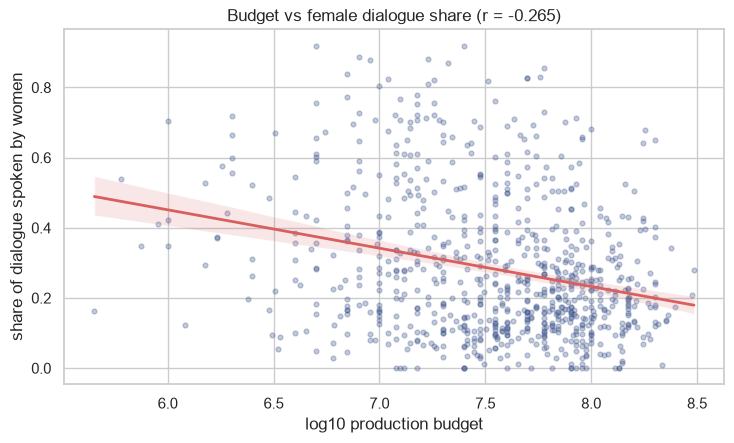

Female dialogue share by budget quintile:

                mean     sd  films
log_budget                        
Q1 (cheapest)  0.361  0.222    160
Q2             0.318  0.230    165
Q3             0.278  0.199    154
Q4             0.238  0.164    168
Q5 (priciest)  0.214  0.137    151


In [15]:
fig, ax = plt.subplots(figsize=(7.5, 4.6))
sns.regplot(data=df, x="log_budget", y="pct_female_dialogue", ax=ax,
            scatter_kws={"s": 12, "alpha": 0.30, "color": "#3b528b"},
            line_kws={"color": "#d95f5f", "lw": 2})

r = df[["log_budget", "pct_female_dialogue"]].corr().iloc[0, 1]
ax.set_xlabel("log10 production budget")
ax.set_ylabel("share of dialogue spoken by women")
ax.set_title(f"Budget vs female dialogue share (r = {r:.3f})")
fig.tight_layout()
fig.savefig(FIGS / "final_budget_dialogue.png", dpi=150)
plt.show()

budget_q = pd.qcut(df["log_budget"], 5, labels=["Q1 (cheapest)", "Q2", "Q3", "Q4", "Q5 (priciest)"])
print("Female dialogue share by budget quintile:\n")
print(df.groupby(budget_q, observed=True)["pct_female_dialogue"]
        .agg(mean="mean", sd="std", films="size").round(3).to_string())

Here is a plot of budget vs the share of female dialogue.

**The decline is monotonic.** Women's share of dialogue drops consistently as budget rises, from 36.1% in the cheapest fifth of films to 21.4% in the priciest. The scatter isn't as obvious, which is why I include a grouping by budget quintile.

The spread narrows as well, from a standard deviation of 0.222 to 0.137. Cheap films vary a lot in how much women speak. Expensive films more consistently give them fewer lines.

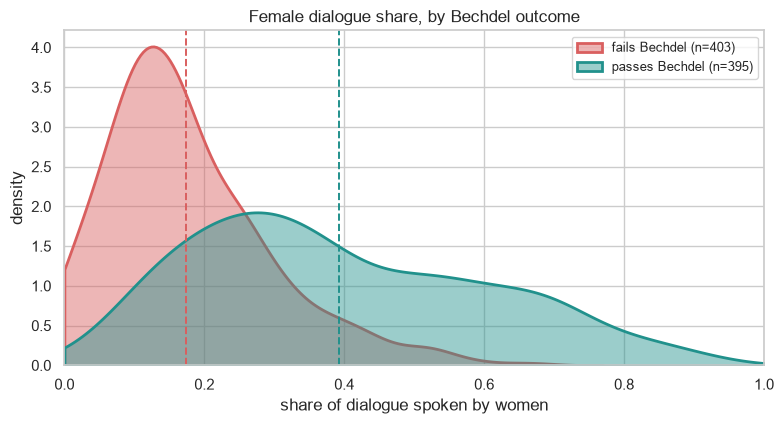

In [16]:
pass_share = df.loc[df["bechdel_pass"], "pct_female_dialogue"]
fail_share = df.loc[~df["bechdel_pass"], "pct_female_dialogue"]

fig, ax = plt.subplots(figsize=(8, 4.4))
# clip=(0,1) stops the KDE extending past bounds.
sns.kdeplot(x=fail_share, fill=True, color="#d95f5f", alpha=0.45, lw=2,
            label=f"fails Bechdel (n={len(fail_share)})", ax=ax, clip=(0, 1))
sns.kdeplot(x=pass_share, fill=True, color="#21918c", alpha=0.45, lw=2,
            label=f"passes Bechdel (n={len(pass_share)})", ax=ax, clip=(0, 1))
ax.axvline(fail_share.mean(), color="#d95f5f", ls="--", lw=1.4)
ax.axvline(pass_share.mean(), color="#21918c", ls="--", lw=1.4)

ax.set_xlabel("share of dialogue spoken by women")
ax.set_ylabel("density")
ax.set_title("Female dialogue share, by Bechdel outcome")
ax.set_xlim(0, 1)
ax.legend(loc="upper right", fontsize=9)
fig.tight_layout()
fig.savefig(FIGS / "final_dialogue_density.png", dpi=150)
plt.show()

Here is a density plot of female dialogue share broken by whether it passes the Bechdel test.

**The two measures of representation are closely related.** Films that fail the Bechdel test average 17.4% female dialogue, while films that pass average 39.3%. The gap between the means is 21.9 percentage points.

This plot shows r = 0.55 from the correlation matrix visually. The two measures are related but not the same. 8.4% of failing films still sit above the median passing film. This implies that a film can give one woman most of the dialogue and still fail, because there is no second woman for her to talk to.

The overlap between the measures is why the classification model leaves out dialogue. Predicting whether a film passes the Bechdel test from the percentage of female dialogue is more about how those measures are defined than about the films.

## 4. Test Statistics

### a. Develop a hypothesis and select the appropriate test statistics

**Hypothesis 1 — continuous outcome, two independent groups.**

- **H₀:** mean log₁₀ domestic gross is equal for films that pass the Bechdel test and films that fail it.
- **H₁:** the two means differ.
- **α = 0.05**, two-tailed.

**Test selected: Welch's two-sample t-test.** The comparison is between the means of one continuous variable across two independent, unpaired groups. Welch's variant is always the safer choice because it does not assume the two groups have equal variances. The test runs on the log scale, because the log distribution is approximately symmetric. I will also use a **Mann-Whitney U test** to check if the outcome holds if the distributions were not normal.

**Hypothesis 2 — two categorical variables.**

- **H₀:** Bechdel pass/fail is independent of MPAA rating.
- **H₁:** the two are associated.

**Test selected: Pearson's chi-squared test of independence**, the test for association in a contingency table of two categorical variables.

In [17]:
# Split log gross into the two Bechdel groups.
grp_pass = df.loc[df["bechdel_pass"], "log_dom"]
grp_fail = df.loc[~df["bechdel_pass"], "log_dom"]

print("Group summaries — log10 domestic gross\n")
print(pd.DataFrame({
    "n": [len(grp_pass), len(grp_fail)],
    "mean": [grp_pass.mean(), grp_fail.mean()],
    "std": [grp_pass.std(), grp_fail.std()],
    "median": [grp_pass.median(), grp_fail.median()],
}, index=["Bechdel pass", "Bechdel fail"]).round(4).to_string())

Group summaries — log10 domestic gross

                n    mean     std  median
Bechdel pass  395  7.6766  0.5627  7.7193
Bechdel fail  403  7.6904  0.5584  7.7844


### b. Assumptions of each test, and whether they hold

In [18]:
print("ASSUMPTION 1 — Check for normality within each group using the Shapiro-Wilk test.")
print("  H0: the group is drawn from a normal distribution\n")

# Test pass for normality and print skew/kurt.
W_pass, p_pass = stats.shapiro(grp_pass)
verdict_pass = "REJECT normality" if p_pass < 0.05 else "CANNOT reject normality"
print(f"  Passes the Bechdel test: W = {W_pass:.4f}, p = {p_pass:.3g}  -> {verdict_pass}")
print(f"    (skew {grp_pass.skew():+.3f}, kurtosis {grp_pass.kurt():+.3f})")

# Test fail for normality and print skew/kurt.
W_fail, p_fail = stats.shapiro(grp_fail)
verdict_fail = "REJECT normality" if p_fail < 0.05 else "CANNOT reject normality"
print(f"  Fails the Bechdel test:  W = {W_fail:.4f}, p = {p_fail:.3g}  -> {verdict_fail}")
print(f"    (skew {grp_fail.skew():+.3f}, kurtosis {grp_fail.kurt():+.3f})")

print("\n\nASSUMPTION 2 — Check for equal variances using Levene's test, median-centered since we reject normality.")
print("  H0: the two groups have equal variance\n")
L, pL = stats.levene(grp_pass, grp_fail, center="median")
verdict = "REJECT equal variance" if pL < 0.05 else "CANNOT reject, therefore equal variance is defendable."
print(f"  Levene W = {L:.4f}, p = {pL:.4f}  -> {verdict}")
print(f"  variance ratio (passes/fails Bechdel) = {grp_pass.var() / grp_fail.var():.3f}")

print("\n\nASSUMPTION 3 — Check for independence of observations.")
print(f"  Each row is a distinct film; no film appears twice: "
      f"{df['imdb_id'].is_unique}")

ASSUMPTION 1 — Check for normality within each group using the Shapiro-Wilk test.
  H0: the group is drawn from a normal distribution

  Passes the Bechdel test: W = 0.9676, p = 1.13e-07  -> REJECT normality
    (skew -0.807, kurtosis +1.806)
  Fails the Bechdel test:  W = 0.9229, p = 1.58e-13  -> REJECT normality
    (skew -1.341, kurtosis +3.431)


ASSUMPTION 2 — Check for equal variances using Levene's test, median-centered since we reject normality.
  H0: the two groups have equal variance

  Levene W = 0.6852, p = 0.4080  -> CANNOT reject, therefore equal variance is defendable.
  variance ratio (passes/fails Bechdel) = 1.016


ASSUMPTION 3 — Check for independence of observations.
  Each row is a distinct film; no film appears twice: True


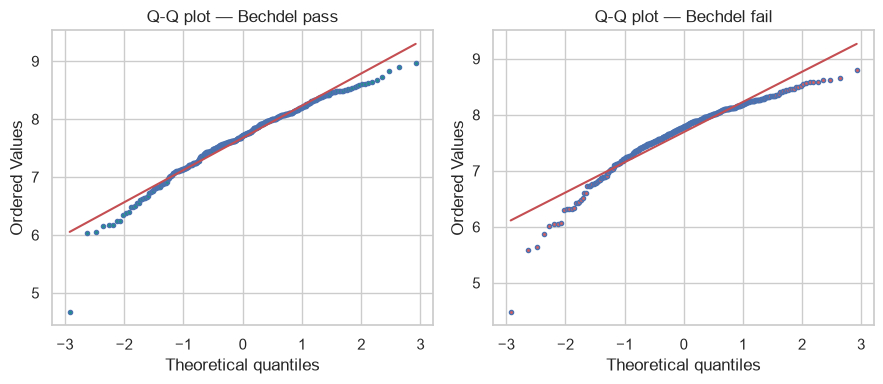

In [19]:
# Visual check on normality, since Shapiro-Wilk is sensitive at large n.
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for ax, (name, s, colour) in zip(axes,
                                 [("Bechdel pass", grp_pass, "#21918c"),
                                  ("Bechdel fail", grp_fail, "#d95f5f")]):
    stats.probplot(s, dist="norm", plot=ax)
    ax.get_lines()[0].set_markerfacecolor(colour)
    ax.get_lines()[0].set_markersize(3.0)
    ax.set_title(f"Q-Q plot — {name}")
fig.tight_layout()
fig.savefig(FIGS / "final_test_assumptions.png", dpi=150)
plt.show()

**Do the assumptions hold?**

- **Normality is formally violated.** Shapiro-Wilk rejects for both groups (p < 10⁻⁶). The Q-Q plots explain: both groups are left-skewed on the log scale (−0.81 and −1.34) with a tail of low-grossing films moving from the diagonal at the bottom left.
- **The violation isn't fatal.** The t-test relies on the sampling distribution of the *mean* being normal, not the actual data. With ample sample sizes, the Central Limit Theorem makes that sampling distribution approximately normal despite the original skew. To confirm the conclusion is not dependent on this, I also run a **Mann-Whitney U test** in the next section.
- **Equal variance holds.** Levene's test does not reject (p = 0.408) and the variance ratio is 1.016.
- **Independence holds** because there is one row per film verified unique.

### c. Test statistics, p-values, and conclusion

In [20]:
t_result = stats.ttest_ind(grp_pass, grp_fail, equal_var=False)
t_stat, p_t, welch_df = t_result.statistic, t_result.pvalue, t_result.df

# Cohen's d — mean difference in pooled standard deviations.
diff_log = grp_pass.mean() - grp_fail.mean()
cohen_d = diff_log / np.sqrt((grp_pass.var() + grp_fail.var()) / 2)

print("HYPOTHESIS 1 — Welch's two-sample t-test")
print(f"  t = {t_stat:.4f},  df = {welch_df:.1f},  p = {p_t:.4f}")
print(f"  mean difference (log10) = {diff_log:+.4f}"
      f"  ->  {100 * (10 ** diff_log - 1):+.2f}% in dollar terms")
print(f"  Cohen's d = {cohen_d:+.4f}  (|d| < 0.2 is a negligible effect)")
print(f"  Decision at alpha = 0.05: {'REJECT H0' if p_t < 0.05 else 'FAIL TO REJECT H0'}")

U, p_u = stats.mannwhitneyu(grp_pass, grp_fail, alternative="two-sided")
print(f"\n  NON-PARAMETRIC CHECK — Mann-Whitney U = {U:,.0f}, p = {p_u:.4f}"
      f"  -> {'reject' if p_u < 0.05 else 'agrees: fail to reject'}")

print("\n\nHYPOTHESIS 2 — chi-squared test of independence")
# Drop the 87 rows with no MPAA rating.
sub = df.dropna(subset=["mpaa_rating"])
ct = pd.crosstab(sub["mpaa_rating"], sub["bechdel_pass"])
chi2, p_c, dof_c, expected = stats.chi2_contingency(ct)
print("\n  Observed counts:")
print(ct.to_string())
print(f"\n  chi2 = {chi2:.4f},  df = {dof_c},  p = {p_c:.4f},  N = {len(sub)}")
print(f"  smallest expected cell count = {expected.min():.2f} (rule of thumb: >= 5)")
print(f"  Decision at alpha = 0.05: {'REJECT H0' if p_c < 0.05 else 'FAIL TO REJECT H0'}")
print("\n  Pass rate by MPAA rating:")
print((ct[True] / ct.sum(axis=1)).round(3).to_string())

HYPOTHESIS 1 — Welch's two-sample t-test
  t = -0.3485,  df = 795.4,  p = 0.7275
  mean difference (log10) = -0.0138  ->  -3.14% in dollar terms
  Cohen's d = -0.0247  (|d| < 0.2 is a negligible effect)
  Decision at alpha = 0.05: FAIL TO REJECT H0

  NON-PARAMETRIC CHECK — Mann-Whitney U = 76,906, p = 0.4094  -> agrees: fail to reject


HYPOTHESIS 2 — chi-squared test of independence

  Observed counts:
bechdel_pass  False  True 
mpaa_rating               
G                 8      2
PG               33     41
PG-13           108    131
R               206    182

  chi2 = 8.1614,  df = 3,  p = 0.0428,  N = 711
  smallest expected cell count = 4.99 (rule of thumb: >= 5)
  Decision at alpha = 0.05: REJECT H0

  Pass rate by MPAA rating:
mpaa_rating
G        0.200
PG       0.554
PG-13    0.548
R        0.469


**Hypothesis 1 — fail to reject.** t(795.4) = −0.35, p = 0.727. There is no detectable difference in raw domestic gross between films that pass the Bechdel test and films that fail. Cohen's d is −0.025, which is negligible regardless. Mann-Whitney U agrees (p = 0.409), so the distribution doesn't need to meet the normality assumption to get an accurate result. 

**This null result is very important, but it's not the end of the project.** If you stopped here, you might believe that representation is unrelated to revenue. The bivariate analysis already suggested that to be incorrect: budget correlates positively with gross (r = 0.66) and negatively with Bechdel rating (r = −0.16). Budget is a **confounder**; passing films are made more cheaply, and cheaper films earn less. The next section tests the same question with budget held fixed. The contrast between the two results is the most significant finding of this report.

**Hypothesis 2 — reject.** χ²(3) = 8.16, p = 0.043. Bechdel outcome is not independent of MPAA rating. R-rated films pass at 46.9% while PG films pass at 55.4%. However, the smallest expected cell count is 4.99, which is just a hair under the conventional minimum of 5 (there were only 10 G-rated films in the sample). The result is then suggestive rather than firm. A similar pattern shows up when using rating to predict if a film passes the Bechdel test in 5(b).

## 5. Regression and Classification

### a. Regression Analysis

#### i. Select an appropriate regression model based on the variable selected

The outcome, log₁₀ domestic gross, is continuous and approximately symmetric after transformation, so I'll use **ordinary least squares**. The specification below was written prior to seeing any model result.

> **Model 1 (M1):** `log_dom ~ bechdel_pass + log_budget + year_c`
> 
> **Model 2 (M2):** `log_dom ~ pfd_10pp + log_budget + year_c`
>
> Controls: log₁₀ production budget and centered release year to absorb price-level drift.
>
> Estimator: OLS with **HC3 robust standard errors**. Standard OLS assumes films scatter around the fitted line by the same amount at every budget level, but that is not true here. Cheap films vary about twice as widely as expensive ones. HC3 corrects the uncertainty estimates for that.
>
> Four checks were pre-declared: swap to worldwide gross, swap to inflation-adjusted gross, treat rating as ordinal, and add genre dummies. No other models were fit.

#### ii. Run the regression model and evaluate it with performance metrics

In [21]:
m1 = smf.ols("log_dom ~ pass_ + log_budget + year_c", data=df).fit(cov_type="HC3")
print("M1 — PRIMARY MODEL: Bechdel pass, controlling for budget and year\n")
print(m1.summary().tables[1])
print(f"\nN = {int(m1.nobs)},  R2 = {m1.rsquared:.4f},  adj R2 = {m1.rsquared_adj:.4f}")
print(f"F = {m1.fvalue:.2f},  AIC = {m1.aic:.1f}")

b = m1.params["pass_"]; lo, hi = m1.conf_int().loc["pass_"]
print(f"\nbechdel_pass coefficient = {b:.4f}  [95% CI {lo:.4f}, {hi:.4f}],  p = {m1.pvalues['pass_']:.4f}")
# 10**b - 1 converts a log10 coefficient to a percentage difference.
print(f"As a percentage difference in gross at fixed budget and year: "
      f"{100 * (10 ** b - 1):+.1f}%  [CI {100 * (10 ** lo - 1):+.1f}%, {100 * (10 ** hi - 1):+.1f}%]")

M1 — PRIMARY MODEL: Bechdel pass, controlling for budget and year

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      1.8572      0.306      6.078      0.000       1.258       2.456
pass_          0.0853      0.030      2.849      0.004       0.027       0.144
log_budget     0.7722      0.039     19.780      0.000       0.696       0.849
year_c        -0.0080      0.002     -3.552      0.000      -0.012      -0.004

N = 798,  R2 = 0.4539,  adj R2 = 0.4518
F = 136.93,  AIC = 864.2

bechdel_pass coefficient = 0.0853  [95% CI 0.0266, 0.1440],  p = 0.0044
As a percentage difference in gross at fixed budget and year: +21.7%  [CI +6.3%, +39.3%]


In [22]:
m2 = smf.ols("log_dom ~ pfd_10pp + log_budget + year_c", data=df).fit(cov_type="HC3")
print("M2 — SECONDARY MODEL: female dialogue share (continuous)\n")
print(m2.summary().tables[1])
print(f"\nN = {int(m2.nobs)},  R2 = {m2.rsquared:.4f}")

b2 = m2.params["pfd_10pp"]; lo2, hi2 = m2.conf_int().loc["pfd_10pp"]
print(f"\nPer +10 percentage points of female dialogue: {100 * (10 ** b2 - 1):+.1f}% gross "
      f"[CI {100 * (10 ** lo2 - 1):+.1f}%, {100 * (10 ** hi2 - 1):+.1f}%],  p = {m2.pvalues['pfd_10pp']:.4f}")

M2 — SECONDARY MODEL: female dialogue share (continuous)

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      1.9480      0.319      6.101      0.000       1.322       2.574
pfd_10pp       0.0028      0.009      0.323      0.747      -0.014       0.020
log_budget     0.7645      0.040     18.986      0.000       0.686       0.843
year_c        -0.0077      0.002     -3.430      0.001      -0.012      -0.003

N = 798,  R2 = 0.4483

Per +10 percentage points of female dialogue: +0.7% gross [CI -3.2%, +4.7%],  p = 0.7467


In [23]:
# The four pre-declared robustness checks.
results = {"M1 domestic (primary)": m1}
results["R1 worldwide gross"] = smf.ols("log_ww ~ pass_ + log_budget + year_c",
                                        data=df).fit(cov_type="HC3")
# R2 runs on the 787 films with a positive inflation-adjusted gross.
r2df = df[df["gross_infl_adj_musd"] > 0].copy()
r2df["log_adj"] = np.log10(r2df["gross_infl_adj_musd"])
results["R2 inflation-adjusted"] = smf.ols("log_adj ~ pass_ + log_budget + year_c",
                                           data=r2df).fit(cov_type="HC3")
r4df = df.dropna(subset=["genre"])
results["R4 + genre controls"] = smf.ols("log_dom ~ pass_ + log_budget + year_c + C(genre)",
                                         data=r4df).fit(cov_type="HC3")

rows = []
for name, m in results.items():
    bb = m.params["pass_"]; l, h = m.conf_int().loc["pass_"]
    rows.append({"model": name, "N": int(m.nobs),
                 "% diff in gross": 100 * (10 ** bb - 1),
                 "CI low": 100 * (10 ** l - 1), "CI high": 100 * (10 ** h - 1),
                 "p": m.pvalues["pass_"], "R2": m.rsquared})
print("Robustness of the Bechdel-pass association across pre-declared models\n")
print(pd.DataFrame(rows).round(3).to_string(index=False))

# R3: rating as ordinal.
r3 = smf.ols("log_dom ~ C(bechdel_rating) + log_budget + year_c", data=df).fit(cov_type="HC3")
print("\n\nR3 — rating as an ordinal factor (rating 0 = reference category):\n")
print(r3.summary().tables[1])

Robustness of the Bechdel-pass association across pre-declared models

                model   N  % diff in gross  CI low  CI high     p    R2
M1 domestic (primary) 798           21.707   6.320   39.321 0.004 0.454
   R1 worldwide gross 798           20.859   5.453   38.516 0.006 0.501
R2 inflation-adjusted 787           18.543   4.168   34.902 0.010 0.498
  R4 + genre controls 711           17.354   1.262   36.003 0.033 0.419


R3 — rating as an ordinal factor (rating 0 = reference category):

                             coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------
Intercept                  1.6714      0.328      5.089      0.000       1.028       2.315
C(bechdel_rating)[T.1]     0.0447      0.077      0.581      0.561      -0.106       0.195
C(bechdel_rating)[T.2]     0.1987      0.087      2.284      0.022       0.028       0.369
C(bechdel_rating)[T.3]     0.1625      0.077 

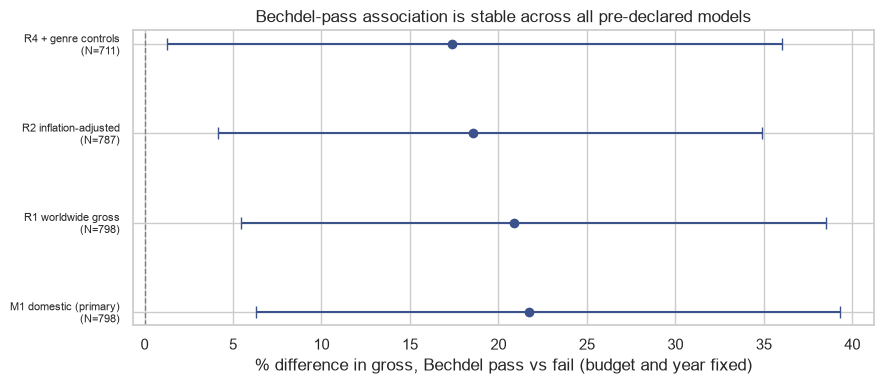

In [24]:
fig, ax = plt.subplots(figsize=(9, 4))
names, est, elo, ehi = [], [], [], []
for name, m in results.items():
    bb = m.params["pass_"]; l, h = m.conf_int().loc["pass_"]
    names.append(f"{name}\n(N={int(m.nobs)})")
    e = 100 * (10 ** bb - 1)
    est.append(e); elo.append(e - 100 * (10 ** l - 1)); ehi.append(100 * (10 ** h - 1) - e)
# errorbar wants distances from the point, not the CI bounds.
ax.errorbar(est, range(len(names)), xerr=[elo, ehi], fmt="o", capsize=4, color="#3b528b")
ax.axvline(0, color="grey", lw=1, ls="--")
ax.set_yticks(range(len(names))); ax.set_yticklabels(names, fontsize=8)
ax.set_xlabel("% difference in gross, Bechdel pass vs fail (budget and year fixed)")
ax.set_title("Bechdel-pass association is stable across all pre-declared models")
fig.tight_layout()
fig.savefig(FIGS / "final_regression_coefficient.png", dpi=150)
plt.show()

#### iii. Interpret your result

**Model 1.** Passing the Bechdel test is associated with **+21.7% higher domestic gross** (95% CI +6.3% to +39.3%, p = 0.004, N = 798, R² = 0.454) once production budget and release year are held fixed. Even though the interval is wide, it does not include zero, so the direction is fairly firm.

**This contradicts the unadjusted t-test in 4(c).** The raw comparison returned p = 0.727 with a point estimate of −3.1%. Adding just that one control turns the null result into a positive one. The mechanism has been established: passing films are made on roughly 25% smaller budgets, and budget strongly drives gross. Holding budget fixed reveals that **passing films earn more than films of comparable cost**.

**Model 2.** Female dialogue *share* shows almost no association with gross (+0.7% per 10 percentage points, CI −3.2% to +4.7%, p = 0.72). The Bechdel *threshold* (two named women who talk to each other about something other than a man) carries the association, while the raw *quantity* of women's speech does not. A film can give women plenty of dialogue without them speaking to one another.

**Robustness.** The association stays true on all four checks: worldwide gross (+20.9%), inflation-adjusted gross (+18.5%), and genre controls (+17.4%). The ordinal model (R3) shows the effect concentrated at ratings 2 and 3.

### b. Classification Model

#### i. Select an appropriate classification model based on the variable selected

**Target variable: `bechdel_pass`.** The regression above asked whether representation predicts revenue, but what about the reverse? Can a film's **production characteristics** predict whether it represents women?

**Model selected: logistic regression.** The target is binary, and logistic regression is normal for a binary outcome. The model will also explain *which* characteristics move the
odds. The classes are almost exactly balanced (50.1% pass), so accuracy is meaningful and no resampling is needed.

**Predictors: genre, MPAA rating, log budget, and release year.** Some that are deliberately excluded: `pct_female_dialogue` and `pct_female_characters`. Those measure how much women speak, and the Bechdel test is a measure of women speaking to each other. It would be circular to include them here.

**Encoding.** `genre` and `mpaa_rating` are categorical and one-hot encoded, with **Drama** and **R** as reference categories. Numeric predictors are standardized in the same pipeline,
so scaling is fit on training folds only.

The sample is the **711 films** with genre and MPAA rating recorded — the 87 missing rows are the WWU-sourced films documented in 2(a).

In [26]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix, classification_report)

# Genre and MPAA are missing for the 87 WWU-sourced rows.
clf_df = df.dropna(subset=["genre", "mpaa_rating"]).copy()
CAT_FEATURES = ["genre", "mpaa_rating"]
NUM_FEATURES = ["log_budget", "year_c"]
X = clf_df[CAT_FEATURES + NUM_FEATURES]
y = clf_df["pass_"]

print("Target: bechdel_pass, predicted from production characteristics only")
print(f"  n = {len(clf_df)} films with genre and MPAA rating")
print(f"  class balance: {int((y == 0).sum())} fail / {int((y == 1).sum())} pass")
print(f"  majority-class baseline accuracy: {max(y.mean(), 1 - y.mean()):.4f}")

# One-hot the categoricals, standardize the numerics.
pre = ColumnTransformer([
    ("cat", OneHotEncoder(drop=["Drama", "R"], handle_unknown="ignore"), CAT_FEATURES),
    ("num", StandardScaler(), NUM_FEATURES),
])
clf = Pipeline([("pre", pre),
                ("logreg", LogisticRegression(max_iter=2000, random_state=42))])

# stratify keeps the pass/fail ratio the sasme in both.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y)
clf.fit(X_train, y_train)
y_pred = clf.predict(X_test)
y_proba = clf.predict_proba(X_test)[:, 1]
print(f"  train n = {len(X_train)},  test n = {len(X_test)}")

Target: bechdel_pass, predicted from production characteristics only
  n = 711 films with genre and MPAA rating
  class balance: 355 fail / 356 pass
  majority-class baseline accuracy: 0.5007
  train n = 533,  test n = 178


#### ii. Conduct the classification analysis and evaluate it with multiple metrics

In [52]:
dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)

print(f"MULTIPLE PERFORMANCE METRICS (held-out test set, n = {len(X_test)})\n")
print(f"  accuracy   {accuracy_score(y_test, y_pred):.4f}"
      f"     (baseline {accuracy_score(y_test, dummy.predict(X_test)):.4f})")
print(f"  precision  {precision_score(y_test, y_pred):.4f}"
      f"     of films predicted to pass, this fraction actually did")
print(f"  recall     {recall_score(y_test, y_pred):.4f}"
      f"     of films that actually pass, this fraction was caught")
print(f"  F1         {f1_score(y_test, y_pred):.4f}"
      f"     harmonic mean of precision and recall")
print(f"  ROC-AUC    {roc_auc_score(y_test, y_proba):.4f}"
      f"     ranking quality")

print("\n\nPer-class report:\n")
print(classification_report(y_test, y_pred, target_names=["fail (0)", "pass (1)"]))

cv = cross_val_score(clf, X, y, cv=StratifiedKFold(5, shuffle=True, random_state=42),
                     scoring="accuracy")
print(f"5-fold cross-validated accuracy: {cv.mean():.4f} +/- {cv.std():.4f}")
print(f"  per fold: {np.round(cv, 4)}")

print("\n\nWhich predictors carry the signal (5-fold CV accuracy):")
for label, cols, cat in [("budget + year only", NUM_FEATURES, []),
                         ("genre + MPAA only", CAT_FEATURES, CAT_FEATURES),
                         ("all four", CAT_FEATURES + NUM_FEATURES, CAT_FEATURES)]:
    steps = []
    if cat:
        steps.append(("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), cat))
    num = [c for c in cols if c in NUM_FEATURES]
    if num:
        steps.append(("num", StandardScaler(), num))
    p = Pipeline([("pre", ColumnTransformer(steps)),
                  ("logreg", LogisticRegression(max_iter=2000, random_state=42))])
    s = cross_val_score(p, clf_df[cols], y, cv=StratifiedKFold(5, shuffle=True, random_state=42),
                        scoring="accuracy")
    print(f"  {label:20s} {s.mean():.4f}")

MULTIPLE PERFORMANCE METRICS (held-out test set, n = 178)

  accuracy   0.5562     (baseline 0.5000)
  precision  0.5625     of films predicted to pass, this fraction actually did
  recall     0.5056     of films that actually pass, this fraction was caught
  F1         0.5325     harmonic mean of precision and recall
  ROC-AUC    0.5816     ranking quality


Per-class report:

              precision    recall  f1-score   support

    fail (0)       0.55      0.61      0.58        89
    pass (1)       0.56      0.51      0.53        89

    accuracy                           0.56       178
   macro avg       0.56      0.56      0.56       178
weighted avg       0.56      0.56      0.56       178

5-fold cross-validated accuracy: 0.5879 +/- 0.0369
  per fold: [0.5594 0.5423 0.5775 0.6197 0.6408]


Which predictors carry the signal (5-fold CV accuracy):
  budget + year only   0.5527
  genre + MPAA only    0.5851
  all four             0.6062


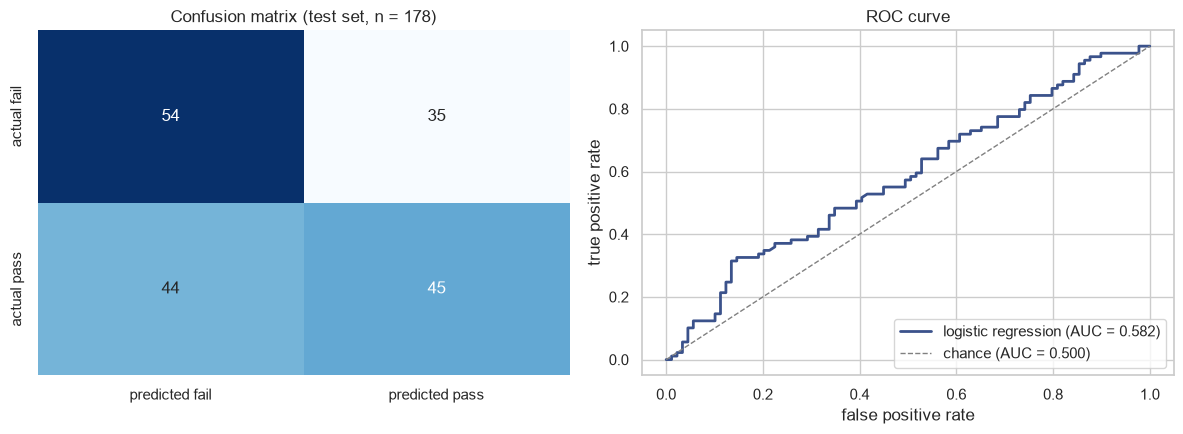

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[0],
            xticklabels=["predicted fail", "predicted pass"],
            yticklabels=["actual fail", "actual pass"])
axes[0].set_title(f"Confusion matrix (test set, n = {len(X_test)})")

fpr, tpr, _ = roc_curve(y_test, y_proba)
axes[1].plot(fpr, tpr, color="#3b528b", lw=2,
             label=f"logistic regression (AUC = {roc_auc_score(y_test, y_proba):.3f})")
axes[1].plot([0, 1], [0, 1], color="grey", ls="--", lw=1, label="chance (AUC = 0.500)")
axes[1].set_xlabel("false positive rate"); axes[1].set_ylabel("true positive rate")
axes[1].set_title("ROC curve"); axes[1].legend(loc="lower right")

fig.tight_layout()
fig.savefig(FIGS / "final_classification.png", dpi=150)
plt.show()

In [53]:
names = list(clf.named_steps["pre"].get_feature_names_out())
coefs = pd.Series(clf.named_steps["logreg"].coef_[0], index=names).sort_values(ascending=False)
print("Logistic regression coefficients (log-odds; reference = Drama, rated R)\n")
print(coefs.round(3).to_string())

print("\n\nBechdel pass rate by genre:\n")
print(clf_df.groupby("genre")["bechdel_pass"]
      .agg(pass_rate="mean", films="size").round(3).to_string())
print("\nBechdel pass rate by MPAA rating:\n")
print(clf_df.groupby("mpaa_rating")["bechdel_pass"]
      .agg(pass_rate="mean", films="size").round(3).to_string())

Logistic regression coefficients (log-odds; reference = Drama, rated R)

cat__genre_Horror         1.241
cat__mpaa_rating_PG       1.052
cat__mpaa_rating_PG-13    0.773
num__year_c               0.124
cat__genre_Comedy        -0.029
cat__genre_Action        -0.040
cat__mpaa_rating_G       -0.042
num__log_budget          -0.303
cat__genre_Adventure     -0.393


Bechdel pass rate by genre:

           pass_rate  films
genre                      
Action         0.377    138
Adventure      0.414     87
Comedy         0.539    141
Drama          0.514    280
Horror         0.738     65

Bechdel pass rate by MPAA rating:

             pass_rate  films
mpaa_rating                  
G                0.200     10
PG               0.554     74
PG-13            0.548    239
R                0.469    388


#### iii. Interpret your result

**The model barely beats chance.** Test accuracy is 55.6% against 50.0%, with ROC-AUC 0.582. Those are weak numbers. **How a film is packaged tells you little about whether it represents
women.** The practical consequence is that representation has to be measured, not inferred.


**The signal that's there comes from categories.** Splitting the predictors shows budget and year alone reach 55.3%, while genre and MPAA alone reach 58.5%.

**Horror has the most representation.** It carries the largest coefficient (+1.24 log-odds against a Drama reference) and passes at **73.8%**. Because there are only 65 horror films, it's not a super precise estimate, but it's still a large gap and consistent to the genre. Family-friendly ratings tend to represent women more: PG films pass at 55.4% and PG-13 at
54.8%, against 46.9% for R. G-rated films are estimated to be 20.0%, but there were only 10 G-rated films in the sample.

**Budget is negative (−0.30).** Bigger films represent women less.

**Precision (0.563) and recall (0.506) are both near 0.5,** and the confusion matrix is nearly evenly split. The model has no strong bias; it just doesn't do a good job at separating.

## 6. Advanced Analysis Techniques

### a. Clustering Analysis

#### i. Select an appropriate clustering method, with PCA to visualize the clusters

**Method selected: k-means.** k-means sorts points into groups by their distance to a center. It works when the groups are compact clumps. That fits this data. All four clustering variables are numeric, and after the log transform, they form roughly oval clouds rather than curved or stringy ones. k-means is also the easiest method to explain. Each group is summarized by its center, and those centers easily convert back to dollars and percentages.

**You must standardize.** k-means minimizes "Euclidean distance", and `production_budget` ranges in the tens of millions while `pct_female_dialogue` spans 0 to 0.92. Without scaling, budget would account for nearly all the distance and the clusters would basically be a budget ranking.

**Clustering variables:** log budget, log domestic gross, female dialogue share, and female character share. I've left out `bechdel_rating` deliberately to compare against the clusters.

**Choosing k.** I use both an elbow plot and silhouette scores to determine k.

Choosing k — elbow (inertia) and silhouette

 k   inertia  silhouette
 2 2001.4141      0.3553
 3 1564.0600      0.3241
 4 1312.9780      0.2675
 5 1146.2022      0.2474
 6 1038.1221      0.2377
 7  935.4576      0.2399


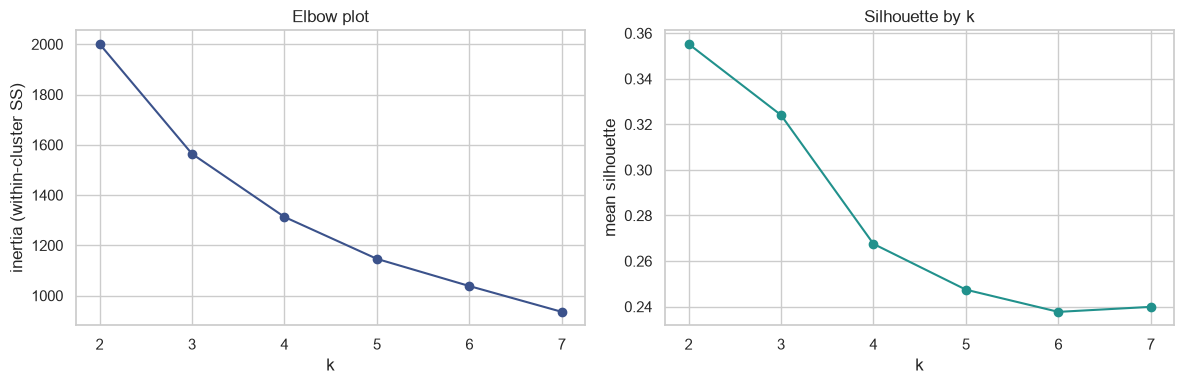

In [30]:
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

CLUSTER_FEATURES = ["log_budget", "log_dom",
                    "pct_female_dialogue", "pct_female_characters"]

# Standardize.
X_clust = StandardScaler().fit_transform(df[CLUSTER_FEATURES])

scan = []
# Inertia and silhouette across candidate k.
for k in range(2, 8):
    km_k = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X_clust)
    scan.append({"k": k, "inertia": km_k.inertia_,
                 "silhouette": silhouette_score(X_clust, km_k.labels_)})
scan = pd.DataFrame(scan)
print("Choosing k — elbow (inertia) and silhouette\n")
print(scan.round(4).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(scan["k"], scan["inertia"], "o-", color="#3b528b")
axes[0].set_xlabel("k"); axes[0].set_ylabel("inertia (within-cluster SS)")
axes[0].set_title("Elbow plot")
axes[1].plot(scan["k"], scan["silhouette"], "o-", color="#21918c")
axes[1].set_xlabel("k"); axes[1].set_ylabel("mean silhouette")
axes[1].set_title("Silhouette by k")
fig.tight_layout()
fig.savefig(FIGS / "final_cluster_selection.png", dpi=150)
plt.show()

**Despite not having the highest silhouette score, I am choosing k = 3.** Silhouette is highest at k = 2 (0.355) with k = 3 close (0.324). The two-cluster solution splits the sample into "big-budget, low female dialogue" (504 films, 35.5% pass) and "small-budget, high female dialogue" (294 films, 73.5% pass). But that pairs budget and representation one to one.

The three-cluster solution separates them slightly. It isolates a group of **small-budget films that are also male-dominated**. Since the research question is about how budget and representation relate, I prefer a solution that keeps them distinct. The difference in silhouette score is a modest 0.03, and I understand this is more of a judgment call for interpretation rather than the best possible clustering solution.

In [31]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10).fit(X_clust)
df["cluster"] = kmeans.labels_

print(f"Cluster sizes: {df['cluster'].value_counts().sort_index().to_dict()}")
print(f"Mean silhouette at k=3: {silhouette_score(X_clust, kmeans.labels_):.4f}\n")

print("Cluster centers, read back in original units:\n")
centers = df.groupby("cluster").agg(
    films=("cluster", "size"),
    mean_budget_M=("production_budget", lambda s: s.mean() / 1e6),
    mean_domestic_M=("domestic_gross", lambda s: s.mean() / 1e6),
    pct_female_dialogue=("pct_female_dialogue", "mean"),
    pct_female_characters=("pct_female_characters", "mean"),
    bechdel_pass_rate=("bechdel_pass", "mean"),
)
print(centers.round(3).to_string())

Cluster sizes: {0: 192, 1: 424, 2: 182}
Mean silhouette at k=3: 0.3241

Cluster centers, read back in original units:

         films  mean_budget_M  mean_domestic_M  pct_female_dialogue  pct_female_characters  bechdel_pass_rate
cluster                                                                                                      
0          192         15.705           21.714                0.236                  0.294              0.438
1          424         83.818          130.488                0.182                  0.226              0.361
2          182         35.666           61.493                0.566                  0.522              0.868


**Why PCA.** There are four clustering variables, and I can't draw a four-dimensional scatter plot. PCA builds new axes out of the original four. Each new axis is a weighted blend of all four variables. The first axis is drawn in the direction where the data spreads out the most, and the second captures what's left over.

Plotting those first two axes gives a flat picture that keeps most of the information. Here PC1 holds 54.9% of the total spread and PC2 holds 30.8%, so the plot below preserves 85.8% of what was in the original four dimensions. The remaining 14.2% is not shown.

**PCA is only used for the picture.** The clusters were built on all four variables. PCA does not change them and plays no part in the clustering.

PCA explained variance: PC1 0.549, PC2 0.308, cumulative 0.858

PCA loadings — what each component represents:

                         PC1    PC2
log_budget            -0.502  0.471
log_dom               -0.445  0.578
pct_female_dialogue    0.514  0.493
pct_female_characters  0.535  0.448


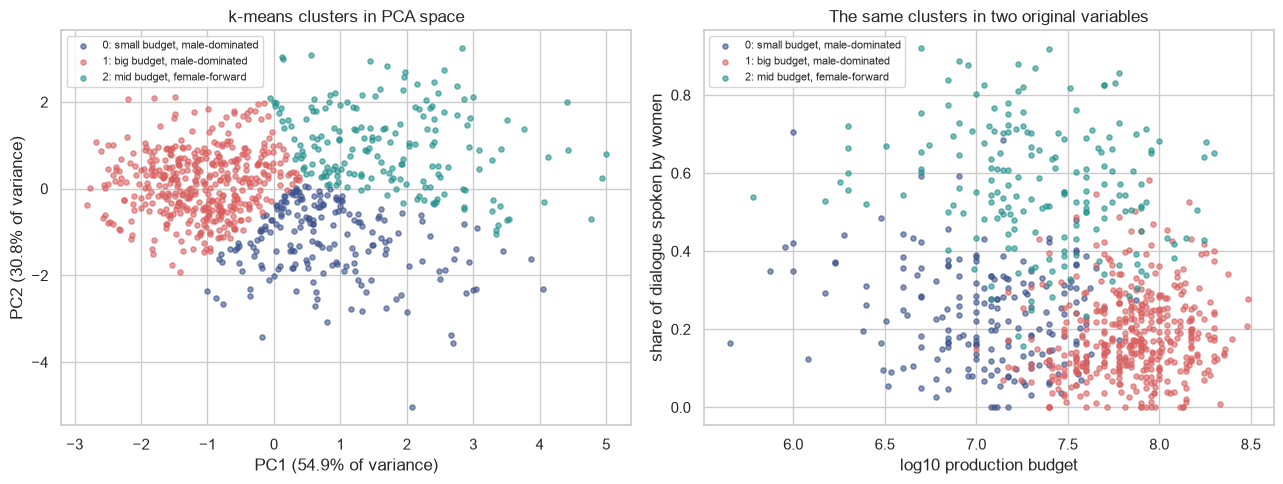

In [32]:
# PCA only projects 4 features to 2 for plotting; clusters used all 4.
pca = PCA(n_components=2).fit(X_clust)
coords = pca.transform(X_clust)
print(f"PCA explained variance: PC1 {pca.explained_variance_ratio_[0]:.3f}, "
      f"PC2 {pca.explained_variance_ratio_[1]:.3f}, "
      f"cumulative {pca.explained_variance_ratio_.sum():.3f}\n")
print("PCA loadings — what each component represents:\n")
print(pd.DataFrame(pca.components_.T, index=CLUSTER_FEATURES,
                   columns=["PC1", "PC2"]).round(3).to_string())

labels = {0: "0: small budget, male-dominated",
          1: "1: big budget, male-dominated",
          2: "2: mid budget, female-forward"}
palette = {0: "#3b528b", 1: "#d95f5f", 2: "#21918c"}

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for c in sorted(df["cluster"].unique()):
    m = df["cluster"] == c
    axes[0].scatter(coords[m, 0], coords[m, 1], s=14, alpha=0.6,
                    color=palette[c], label=labels[c])
axes[0].set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%} of variance)")
axes[0].set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%} of variance)")
axes[0].set_title("k-means clusters in PCA space")
axes[0].legend(fontsize=8, loc="best")

for c in sorted(df["cluster"].unique()):
    m = df["cluster"] == c
    axes[1].scatter(df.loc[m, "log_budget"], df.loc[m, "pct_female_dialogue"],
                    s=14, alpha=0.6, color=palette[c], label=labels[c])
axes[1].set_xlabel("log10 production budget")
axes[1].set_ylabel("share of dialogue spoken by women")
axes[1].set_title("The same clusters in two original variables")
axes[1].legend(fontsize=8, loc="best")

fig.tight_layout()
fig.savefig(FIGS / "final_clusters.png", dpi=150)
plt.show()

#### ii. Evaluate the model and interpret the grouping

In [33]:
print("EXTERNAL VALIDATION — cluster membership vs Bechdel outcome")
print("(bechdel_rating was NOT used to build the clusters)\n")
ct = pd.crosstab(df["cluster"], df["bechdel_pass"], margins=True)
print(ct.to_string())
print("\nBechdel pass rate by cluster:")
print((df.groupby("cluster")["bechdel_pass"].mean()).round(3).to_string())

chi2_cl, p_cl, dof_cl, _ = stats.chi2_contingency(
    pd.crosstab(df["cluster"], df["bechdel_pass"]))
print(f"\nchi-squared test of independence: chi2 = {chi2_cl:.2f}, "
      f"df = {dof_cl}, p = {p_cl:.3g}")

EXTERNAL VALIDATION — cluster membership vs Bechdel outcome
(bechdel_rating was NOT used to build the clusters)

bechdel_pass  False  True  All
cluster                       
0               108    84  192
1               271   153  424
2                24   158  182
All             403   395  798

Bechdel pass rate by cluster:
cluster
0    0.438
1    0.361
2    0.868

chi-squared test of independence: chi2 = 134.43, df = 2, p = 6.43e-30


**Evaluation.** Mean silhouette at k = 3 is 0.324. That is a weak-to-moderate structure; the clusters are real but not sharply separated, which
is expected for continuous variables without natural categories. PC1 and PC2 together capture 85.8% of the variance, so the two-dimensional plot is a fair representation.

The "loadings" show what each axis measures. On PC1, budget and gross are negative (−0.50, −0.45) while the two representation measures are positive (0.51, 0.54). That means films at one end of PC1 are expensive with little female dialogue, and films at the other end are cheaper with more of it. It's the same budget-versus-representation tension we found in section 3.

On PC2, every variable is positive, so it measures overall size. Films high on PC2 are bigger on everything at once.

**Interpreting the three groups:**

| Cluster | n | Mean budget | Mean domestic | Female dialogue | Bechdel pass rate |
|---|---|---|---|---|---|
| 0 — small budget, male-dominated | 192 | \\$15.7M | \\$21.7M | 23.6% | 43.8% |
| 1 — big budget, male-dominated | 424 | \\$83.8M | \\$130.5M | 18.2% | 36.1% |
| 2 — mid budget, female-forward | 182 | \\$35.7M | \\$61.5M | 56.6% | 86.8% |

**The grouping is meaningful, and cluster 0 is why I chose k = 3.** Clusters 0 and 1 are separated by money, and both give women under a quarter of the dialogue and fail the Bechdel test more often than not. **Being a small, inexpensive film does not make a film female-forward.** Cluster 2 is distinct: mid-budget films where women speak 56.6% of the dialogue, passing the Bechdel test at 86.8%.

**There is strong external validation.** Bechdel rating did not assist in making these clusters, yet pass rates across them are 36.1%, 43.8%, and 86.8%, and a chi-squared test rejects independence. The dialogue structure the algorithm also found is on track with the Bechdel ratings; two independently produced measures of representation are agreeing with each other.

However, one limitation: cluster 2 refers to *middle* budgets, not low ones. The female-forward films in this sample don't have tiny budgets; they are mid-scale commercial releases.

### b. Machine Learning approach to Regression or Classification

#### i. Apply a regression model using a machine learning approach

This section asks the same question as 5(a) — predict log₁₀ domestic gross — but with a machine learning method. Both models use the same predictors and the same data, so any difference comes from the algorithm.

**Five-fold cross-validation.** The data is cut into five parts. Each part takes a turn as the test set while the model trains on the other four. Every film gets predicted exactly once, and the reported score is the average of the five runs.

**Model selected: random forest.** A random forest builds hundreds of decision trees and averages them. Each tree splits the data into regions and predicts one value inside each region. OLS fits a single straight relationship and can't fit curves or interactions.

OLS uses a scaler here only so both models are set up the same way.

In [34]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold

ML_FEATURES = ["log_budget", "year_c", "pct_female_dialogue",
               "pct_female_characters", "pass_"]
X_ml = df[ML_FEATURES]
y_ml = df["log_dom"]

# Identical folds for both models so the comparison is like-for-like.
folds = KFold(n_splits=5, shuffle=True, random_state=42)

ols_pipe = Pipeline([("scaler", StandardScaler()), ("ols", LinearRegression())])
forest = RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1)

ols_r2 = cross_val_score(ols_pipe, X_ml, y_ml, cv=folds, scoring="r2")
rf_r2 = cross_val_score(forest, X_ml, y_ml, cv=folds, scoring="r2")
# sklearn returns RMSE negated; flip the sign back.
ols_rmse = -cross_val_score(ols_pipe, X_ml, y_ml, cv=folds,
                            scoring="neg_root_mean_squared_error")
rf_rmse = -cross_val_score(forest, X_ml, y_ml, cv=folds,
                           scoring="neg_root_mean_squared_error")

print("5-FOLD CROSS-VALIDATED PERFORMANCE (identical folds for both models)\n")
print(pd.DataFrame({
    "mean R2": [ols_r2.mean(), rf_r2.mean()],
    "std R2": [ols_r2.std(), rf_r2.std()],
    "mean RMSE (log10)": [ols_rmse.mean(), rf_rmse.mean()],
}, index=["OLS (traditional)", "Random forest (ML)"]).round(4).to_string())

print(f"\nOLS    per-fold R2: {np.round(ols_r2, 3)}")
print(f"Forest per-fold R2: {np.round(rf_r2, 3)}")
print(f"\nDifference in mean R2 (forest - OLS): {rf_r2.mean() - ols_r2.mean():+.4f}")

5-FOLD CROSS-VALIDATED PERFORMANCE (identical folds for both models)

                    mean R2  std R2  mean RMSE (log10)
OLS (traditional)    0.4406  0.1020             0.4156
Random forest (ML)   0.3655  0.1083             0.4427

OLS    per-fold R2: [0.387 0.545 0.39  0.306 0.574]
Forest per-fold R2: [0.273 0.475 0.325 0.242 0.512]

Difference in mean R2 (forest - OLS): -0.0751


#### ii. Evaluate the model performance metrics and interpret the results

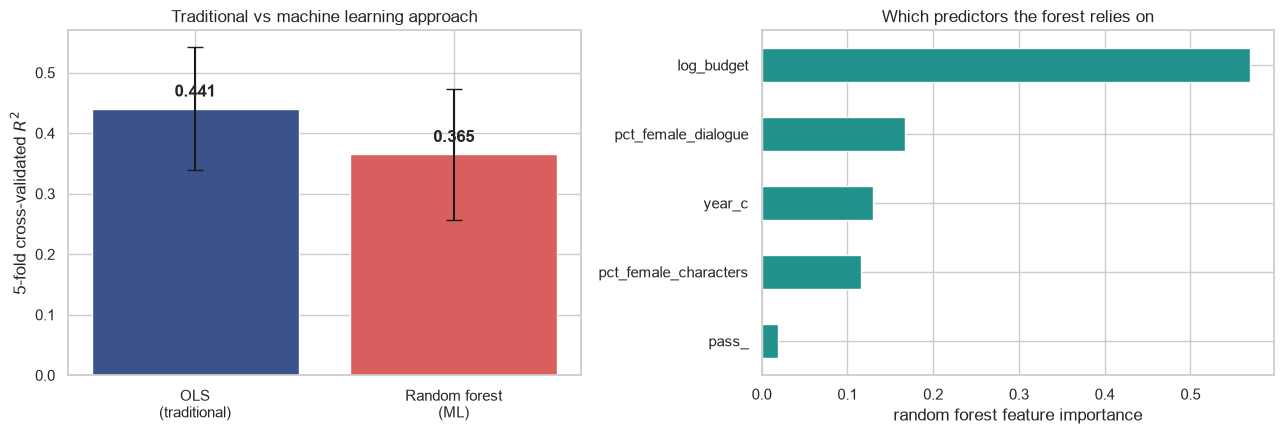

Random forest feature importances:

log_budget               0.5690
pct_female_dialogue      0.1671
year_c                   0.1297
pct_female_characters    0.1158
pass_                    0.0185


In [35]:
# Refit on all rows to read feature importances.
forest_full = RandomForestRegressor(n_estimators=300, random_state=42,
                                    n_jobs=-1).fit(X_ml, y_ml)
importances = pd.Series(forest_full.feature_importances_,
                        index=ML_FEATURES).sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].bar(["OLS\n(traditional)", "Random forest\n(ML)"],
            [ols_r2.mean(), rf_r2.mean()],
            yerr=[ols_r2.std(), rf_r2.std()], capsize=6,
            color=["#3b528b", "#d95f5f"])
axes[0].set_ylabel("5-fold cross-validated $R^2$")
axes[0].set_title("Traditional vs machine learning approach")
for i, v in enumerate([ols_r2.mean(), rf_r2.mean()]):
    axes[0].text(i, v + 0.02, f"{v:.3f}", ha="center", fontweight="bold")

importances.sort_values().plot.barh(ax=axes[1], color="#21918c")
axes[1].set_xlabel("random forest feature importance")
axes[1].set_title("Which predictors the forest relies on")

fig.tight_layout()
fig.savefig(FIGS / "final_ml_comparison.png", dpi=150)
plt.show()

print("Random forest feature importances:\n")
print(importances.round(4).to_string())

**The machine learning model performs worse than ordinary least squares.** Cross-validated R² is **0.441 for OLS versus 0.366 for the random forest**.

A random forest's advantage is to capture curves and interactions. There isn't much of either in this data. After the log transform, the budget-gross relationship is close to linear. The forest doesn't gain much from its flexibility. The linear model is appropriate for a linear relationship.

OLS ranges from 0.306 to 0.574 across folds and the forest from 0.242 to 0.512. Both vary considerably, and this is why cross-validation exists.

`log_budget` scores 0.569, while `pass_` scores 0.019 (almost no contribution).  Still, 5(a) found that variable statistically significant at +21.7% with p = 0.004.

The two just answer different questions. Importance asks *how much does this variable help me predict an unknown film's gross?* And the answer is barely. The regression coefficient asks *among films with the same budget and release year, how much do passing films differ?* In this case, the answer is meaningfully.

## 7. Data Storytelling

The written narrative is submitted separately as Part 2, per the assignment instructions. See `DSC_530_FinalProject_Narrative_McKee.pdf`. It covers story (7a), has two impact visualizations (7b), and has recommendations (7c).

## 8. Documentation

### a. Documentation of the analysis process

Every section above states the choice made and the reason for it. The full acquisition history for each source, including two that went offline during the project, is recorded in `data/raw/README_provenance.md`. The model specification in 5(a) was written before any model was run, so no result here was chosen after seeing it.

### b. Limitations of the analysis and assumptions made

These are stated as first-class results rather than caveats, because several of
them bound what the headline number means.

1. **Association, not causation.** Nothing here identifies a causal effect. Films that pass the Bechdel test may differ from films that fail in ways that are not captured by budget and year (genre conventions, casting, marketing spend, or director experience). The estimate is a description of a pattern.
2. **Selection funnel.** The sample is compiled from three sources and favors larger films at each join (\\$93M → \\$106M → \\$125M mean gross). Results describe well-documented commercial releases, not films in general.
3. **Volunteer-coded outcome.** Bechdel ratings come from site visitors, and the 2021 mirror has no `dubious` flag to mark disputed entries.
4. **Binary gender coding.** The dialogue data codes every character male or female against IMDb, and ambiguously named characters may be prone to error.
5. **The Bechdel test is a minimum threshold.** It does not reliably measure quality of representation. A film can pass on a single, momentary exchange, and a representative film about one woman can still fail.
6. **A frozen data source.** bechdeltest.com's API was permanently disabled during this project (HTTP 410), so the 2021 mirror is final (films rated after March 2021 are absent). The 2015 cutoff is due to the range in the Pudding data.
7. **Wide confidence interval.** The +21.7% estimate spans +6.3% to +39.3%. The direction is likely firm, but the magnitude is not.
8. **Nominal dollars.** The primary outcome uses nominal gross, relying on controlling for the year to absorb drift. The inflation-adjusted check (+18.5%) confirms that this is a reasonable assumption.

---

## References

Anderson, H., & Daniels, M. (2016). *Film dialogue from 2,000 screenplays, broken
down by gender and age.* The Pudding. https://pudding.cool/2017/03/film-dialogue/

Bechdel Test Movie List. (2021). *Bechdel test data* [Data set]. Accessed via the
TidyTuesday 2021-03-09 mirror. https://bechdeltest.com/ (CC BY-NC 3.0)

Harris, C. R., Millman, K. J., van der Walt, S. J., Gommers, R., Virtanen, P.,
Cournapeau, D., Wieser, E., Taylor, J., Berg, S., Smith, N. J., Kern, R., Picus, M.,
Hoyer, S., van Kerkwijk, M. H., Brett, M., Haldane, A., del Río, J. F., Wiebe, M.,
Peterson, P., … Oliphant, T. E. (2020). Array programming with NumPy. *Nature,
585*(7825), 357–362. https://doi.org/10.1038/s41586-020-2649-2

Hunter, J. D. (2007). Matplotlib: A 2D graphics environment. *Computing in Science
& Engineering, 9*(3), 90–95. https://doi.org/10.1109/MCSE.2007.55

McKinney, W. (2010). Data structures for statistical computing in Python. In
S. van der Walt & J. Millman (Eds.), *Proceedings of the 9th Python in Science
Conference* (pp. 56–61). https://doi.org/10.25080/Majora-92bf1922-00a

Molin, S. (2021). *Hands-on data analysis with pandas* (2nd ed.). Packt Publishing.

Nash Information Services. (2018, 2023). *Movie budgets and financial performance
records* [Data set]. The Numbers. Accessed via the TidyTuesday 2018-10-23 snapshot
and the WWU DATA 311 course mirror. https://www.the-numbers.com/

Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O.,
Blondel, M., Prettenhofer, P., Weiss, R., Dubourg, V., Vanderplas, J., Passos, A.,
Cournapeau, D., Brucher, M., Perrot, M., & Duchesnay, É. (2011). Scikit-learn:
Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825–2830.

Seabold, S., & Perktold, J. (2010). Statsmodels: Econometric and statistical
modeling with Python. In S. van der Walt & J. Millman (Eds.), *Proceedings of the
9th Python in Science Conference* (pp. 92–96).
https://doi.org/10.25080/Majora-92bf1922-011

Virtanen, P., Gommers, R., Oliphant, T. E., Haberland, M., Reddy, T.,
Cournapeau, D., Burovski, E., Peterson, P., Weckesser, W., Bright, J., van der
Walt, S. J., Brett, M., Wilson, J., Millman, K. J., Mayorov, N., Nelson, A. R. J.,
Jones, E., Kern, R., Larson, E., … van Mulbregt, P. (2020). SciPy 1.0: Fundamental
algorithms for scientific computing in Python. *Nature Methods, 17*(3), 261–272.
https://doi.org/10.1038/s41592-019-0686-2

Waskom, M. L. (2021). seaborn: Statistical data visualization. *Journal of Open
Source Software, 6*(60), 3021. https://doi.org/10.21105/joss.03021
